# Independent reproduction: Higgins et al. (2017), Figure 7A and Figure 7B

**Scope:** dSprites, original fully-connected β-VAE, β=4 versus β=1. This notebook independently implements the architecture and visualizes (1) averaged latent response to position/scale/orientation; (2) single-coordinate latent traversals; and (3) learned posterior variance. It **never constructs synthetic example results**.

**Assignment phases:** Phase 1–3 only. **No author or third-party model implementation is used.** Permitted source materials: the original research paper, assignment rubric, official dSprites data, and PyTorch documentation.

Paper: [Higgins et al., ICLR 2017](https://openreview.net/forum?id=Sy2fzU9gl). Official data: [DeepMind dSprites](https://github.com/google-deepmind/dsprites-dataset). The output is **not guaranteed to match** the exact random initialization or training length of the paper; those are not fully stated.

**How to run:** Colab → Runtime → Change runtime type → A100 GPU. Run all cells top-to-bottom, granting Drive access. The run config defaults to **two full-data seeds per β** and **30 complete epochs** per model. It is **not a smoke test**. Checkpointed epochs resume, and figure cells reuse checkpoints and cached posterior statistics. Change `EPOCHS` upward to continue training rather than starting over. Outputs and records save in `MyDrive/beta_vae_figure7_independent/`.

**Important:** Do not label the figures as successful reproductions until you have actually executed training and examined diagnostics. This notebook has been structurally generated and locally smoke-tested for syntax/synthetic tensors, **not** trained on an A100 by the assistant.

## 1. What the paper actually specifies

Appendix A, Table 1 for **2D shapes (VAE)**:

| Component | Specification |
|---|---|
| Input | 4096 flattened binary pixels (64×64×1) |
| Encoder | 4096 → 1200 → 1200 → Gaussian mean/log-variance heads (10 dimensions), ReLU hidden units |
| Decoder | 10 → 1200 → 1200 → 1200 → 4096, tanh hidden units, Bernoulli output |
| Optimizer | **Adagrad**, learning rate **0.01** |
| β | **4** for Figure 7A; **1** for Figure 7B |
| Reconstruction | Bernoulli negative log-likelihood (sum over pixels) |
| Regularizer | KL of 10 diagonal-Gaussian posterior dimensions against standard normal (sum over latents) |

The **minimization** objective (negative of the paper's maximization form) for minibatch \(B\) is

\[
\hat J_\beta = \frac1{|B|}\sum_{x\in B}\left[\sum_{p=1}^{4096}\mathrm{BCEWithLogits}(\ell_p(x),x_p)
+\frac\beta2\sum_{j=1}^{10}\left(\mu_j(x)^2+e^{\log\sigma_j^2(x)}-1-\log\sigma_j^2(x)\right)\right].
\]

Decoder output is **logits**, not tanh probabilities: tanh is used between hidden layers; the Bernoulli likelihood is obtained with `sigmoid(logits)`. Training samples \(z=\mu+\exp(\tfrac12\log\sigma^2)\epsilon\), with \(\epsilon\sim N(0,I)\).

**Paper caption for Figure 7:** columns are ordered by learned Gaussian variance. Position row averages over shapes, scale, rotation (32×32 spatial grid); scale row averages over orientations and positions **separately by shape**; rotation row averages over scale and positions **separately by shape**. The bottom five image rows vary one latent from -3 to 3 while keeping other 9 dimensions fixed at an image's inferred code. **Variance here means mean encoder-predicted posterior variance** \(E_x[\sigma_j^2(x)]\), not empirical variance of inferred means. The paper shows five selected low-variance latents plus an unused latent; here we additionally expose all ten.

**Not fully specified and declared choices:** batch size (256); number of epochs (30 to start, extend based on evidence); training ordering/shuffle and initialization (PyTorch defaults); the exact anchor image (fixed, documented below); the original exact heatmap scaling (shared, zero-centered for all latents); precision flags (float32 baseline by default); exact A100 runtime (benchmark during execution). No validation holdout is created: Figure 7 depends on the complete combinatorial dataset. These are **decisions**, not assertions about Higgins et al. (2017).

In [ ]:
# Configuration: set these BEFORE running training. All seeds train over the FULL dataset.
import os, sys, time, json, math, random, gc, csv, platform, tempfile
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

IS_COLAB = 'google.colab' in sys.modules
if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/beta_vae_figure7_independent')
    DATA_DIR = Path('/content/dsprites_data')   # fast local Colab disk
else:
    ROOT = Path.cwd() / 'beta_vae_figure7_independent'
    DATA_DIR = Path.cwd() / 'dsprites_data'
ROOT.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Full experimental grid: 2 seeds per beta. A third seed can be added later.
BETAS = [4.0, 1.0]
SEEDS = [123, 456]
EPOCHS = 30                     # Increase later to continue from checkpoints.
BATCH_SIZE = 256                # Unspecified in original paper, explicit choice.
LEARNING_RATE = 1e-2             # Specified in the original paper.
Z_DIM = 10
SAVE_EVERY_EPOCHS = 2
LOG_EVERY_STEPS = 200
ANALYSIS_BATCH_SIZE = 2048
CACHE_IMAGES_ON_GPU = True       # uint8 dSprites occupies ~3.0 GB; A100 40GB fits.
USE_BF16 = False                 # Strict float32 baseline; True is an A100 speed deviation.
USE_TF32 = False                 # Strict float32 baseline; True is another speed deviation.

assert EPOCHS > 0 and BATCH_SIZE > 0 and Z_DIM == 10
assert torch.cuda.is_available(), 'Please select a GPU runtime (A100 preferred).'
DEVICE = torch.device('cuda')
if USE_BF16:
    assert torch.cuda.is_bf16_supported(), 'BF16 needs a supported GPU (A100 works).'
torch.backends.cuda.matmul.allow_tf32 = USE_TF32
if hasattr(torch.backends, 'cudnn'):
    torch.backends.cudnn.allow_tf32 = USE_TF32

print('PyTorch:', torch.__version__, 'GPU:', torch.cuda.get_device_name(0))
print('GPU VRAM (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
print('Experiment directory:', ROOT)
print('Planned models:', len(BETAS)*len(SEEDS), 'Full-data epochs/model:', EPOCHS)

Mounted at /content/drive
PyTorch: 2.11.0+cu130 GPU: NVIDIA A100-SXM4-40GB
GPU VRAM (GiB): 39.49
Experiment directory: /content/drive/MyDrive/beta_vae_figure7_independent
Planned models: 4 Full-data epochs/model: 30


In [ ]:
# Persistent experiment records. Run-specific failure events are appended, never invented.
DECISIONS = {
  'paper': 'Higgins et al. (2017), Figure 7A/7B, Appendix A, Table 1',
  'implementation': 'Independent from paper only; no released model code consulted',
  'encoder': 'Flatten-1200(ReLU)-1200(ReLU)-mu/logvar(10)',
  'decoder': '10-1200(tanh)-1200(tanh)-1200(tanh)-4096 Bernoulli logits',
  'optimizer': {'name':'Adagrad', 'lr': LEARNING_RATE},
  'loss': 'mean_over_batch(sum_4096_pixel_BCE + beta * sum_10_KL)',
  'dataset': 'official complete dSprites; original binary images; no normalization/augmentation',
  'batch_size': BATCH_SIZE, 'epochs_target': EPOCHS, 'betas':BETAS, 'seeds':SEEDS,
  'latent_order': 'ascending mean predicted posterior variance E_x[exp(logvar)]',
  'heatmaps': 'x horizontal, y down; response scale symmetric across all latent dimensions',
  'traversal': 'five absolute values in [-3,-1.5,0,1.5,3], other dims = one anchor posterior mean',
  'anchor_classes': {'color':0, 'shape':1, 'scale':3, 'orientation':10, 'x':16, 'y':16},
  'figure_columns': 'five smallest posterior-variance latents + single largest-variance latent; all ten supplementary',
  'precision': {'bf16':USE_BF16,'tf32':USE_TF32},
  'unspecified_in_paper': ['batch size','training duration','exact initialization','exact anchor image',
                          'heatmap color normalization','random seeds','checkpoint schedule'],
  'phase4_code_review_allowed': False,
}
(ROOT/'DECISIONS.json').write_text(json.dumps(DECISIONS, indent=2))
FAILURES_PATH = ROOT/'FAILURE_LOG.md'
if not FAILURES_PATH.exists():
    FAILURES_PATH.write_text("""# Independent β-VAE reproduction: failures and corrections

No model run has been executed yet. Add ONLY actual observed failures, their evidence, fix, and follow-up measurement. Do not fabricate failed attempts.

## Entry template
- Run (β, seed, checkpoint epoch):
- Symptom and evidence (numbers/plot/log):
- Hypothesis (label as a hypothesis):
- Diagnostic performed:
- Code/config change and reason:
- Before/after comparison:
- Unresolved limitation:

## Phase boundary
The independent Phase 3 implementation must be committed before consulting published implementations in Phase 4.
""")

def record_failure(run, symptom, evidence):
    with FAILURES_PATH.open('a') as f:
        f.write(f'\n## {time.strftime("%Y-%m-%d %H:%M:%S")} – {run}\n- Symptom: {symptom}\n- Evidence: {evidence}\n- Correction: PENDING\n')

ENV = {'python':sys.version, 'torch':torch.__version__, 'numpy':np.__version__,
       'cuda':torch.version.cuda, 'gpu':torch.cuda.get_device_name(0),
       'cuda_visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES',''),
       'platform':platform.platform()}
(ROOT/'environment.json').write_text(json.dumps(ENV,indent=2))
print('Experiment decisions, environment, and failure log initialized.')

Experiment decisions, environment, and failure log initialized.


## 2. Download and validate official dSprites

Use the original unaltered NPZ. This *downloads data, not implementation code.* The dataset ordering is `[color, shape, scale, orientation, position X, position Y]`, with sizes `[1,3,6,40,32,32]`. Metadata labels are used **only for the supervised evaluation/visualizations**, never for training. Image cache is `uint8` until each minibatch is cast to float32.

In [ ]:
import urllib.request
DS_NAME = 'dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
DS_URL = ('https://raw.githubusercontent.com/google-deepmind/dsprites-dataset/'
          'master/' + DS_NAME)
DATA_PATH = DATA_DIR / DS_NAME
if not DATA_PATH.exists() or DATA_PATH.stat().st_size < 1_000_000:
    print('Downloading official DeepMind dataset...', DS_URL)
    tmp = DATA_PATH.with_suffix('.part')
    urllib.request.urlretrieve(DS_URL, tmp)
    os.replace(tmp, DATA_PATH)
print('Dataset archive:', DATA_PATH, 'size (MiB):', round(DATA_PATH.stat().st_size/2**20, 1))

# The .npz is compressed, so loading the images decompresses ~3 GB once.
t0 = time.perf_counter()
with np.load(DATA_PATH, allow_pickle=True, encoding='latin1') as ds:
    imgs_np = ds['imgs']
    cls_np = ds['latents_classes'].astype(np.int64, copy=False)
assert imgs_np.shape == (737280, 64, 64), imgs_np.shape
assert cls_np.shape == (737280, 6), cls_np.shape
assert imgs_np.dtype == np.uint8
assert np.array_equal(np.unique(imgs_np[::1000]), np.array([0,1])), 'Images not binary?'
FACTOR_SIZES = (1,3,6,40,32,32)
assert tuple(int(cls_np[:,i].max()+1) for i in range(6)) == FACTOR_SIZES
assert np.array_equal(cls_np[0], [0,0,0,0,0,0])
assert np.array_equal(cls_np[1], [0,0,0,0,0,1]), 'Unexpected factor order'
assert np.array_equal(cls_np[-1], [0,2,5,39,31,31])

# Single GPU uint8 image store, ~3 GiB. Set cache False if GPU memory is limited.
image_tensor_cpu = torch.from_numpy(imgs_np.reshape(-1,4096))
if CACHE_IMAGES_ON_GPU:
    IMAGES = image_tensor_cpu.to(DEVICE, non_blocking=False)
    IMAGE_DEVICE = DEVICE
else:
    IMAGES = image_tensor_cpu  # stays CPU uint8 (batch transfer every training step)
    IMAGE_DEVICE = torch.device('cpu')
CLASSES = torch.from_numpy(cls_np).to(DEVICE)
N = len(IMAGES)
del imgs_np, cls_np, image_tensor_cpu
gc.collect()
print('Loaded', N, 'images in', round(time.perf_counter()-t0,1), 's')
print('image store dtype/device:', IMAGES.dtype, IMAGES.device,
      '| labels:', tuple(CLASSES.shape), CLASSES.device)
print('GPU allocated (GiB):',round(torch.cuda.memory_allocated()/2**30,2))

def get_batch(indices):
    if IMAGES.device.type == 'cuda':
        x = IMAGES.index_select(0,indices)
    else:
        x = IMAGES.index_select(0,indices.cpu()).to(DEVICE,non_blocking=False)
    return x.to(dtype=torch.float32)

Dataset archive: /content/dsprites_data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz size (MiB): 18.4
Loaded 737280 images in 7.1 s
image store dtype/device: torch.uint8 cuda:0 | labels: (737280, 6) cuda:0
GPU allocated (GiB): 2.85


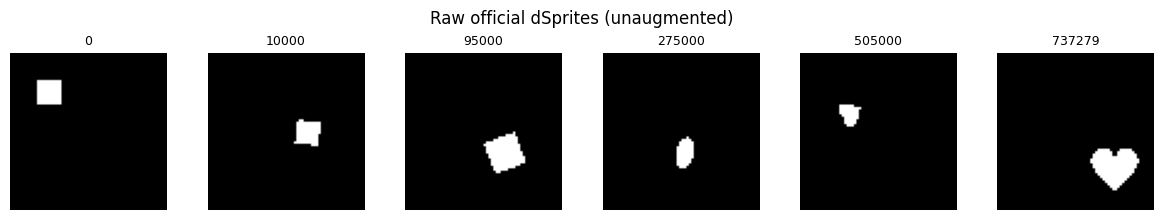

In [ ]:
# Dataset sanity: show six deterministic examples; no transformations of image values.
ids = [0, 10_000, 95_000, 275_000, 505_000, 737279]
xx = get_batch(torch.tensor(ids,device=DEVICE)).cpu().reshape(-1,64,64)
fig, axes = plt.subplots(1,6,figsize=(12,2.2))
for i,ax in enumerate(axes):
    ax.imshow(xx[i], cmap='gray', vmin=0,vmax=1)
    ax.set_title(str(ids[i]),fontsize=9); ax.axis('off')
plt.suptitle('Raw official dSprites (unaugmented)')
plt.tight_layout(); plt.show()

## 3. Original fully connected VAE and numerical unit checks

`logvar` means \(\log\sigma^2\), *not* \(\log\sigma\). Reconstruction uses the Bernoulli log-likelihood summed across all 4096 pixels, whereas KL is summed over the ten latents. Both are only then averaged across the batch. For speed and stability `binary_cross_entropy_with_logits` is used in lieu of explicit sigmoid followed by logarithms.

In [ ]:
class OriginalShapesVAE(nn.Module):
    def __init__(self, z_dim=10):
        super().__init__()
        self.z_dim = z_dim
        self.encoder = nn.Sequential(
            nn.Linear(4096,1200), nn.ReLU(),
            nn.Linear(1200,1200), nn.ReLU(),
        )
        self.to_mu = nn.Linear(1200,z_dim)
        self.to_logvar = nn.Linear(1200,z_dim)
        self.decoder = nn.Sequential(
            nn.Linear(z_dim,1200), nn.Tanh(),
            nn.Linear(1200,1200), nn.Tanh(),
            nn.Linear(1200,1200), nn.Tanh(),
            nn.Linear(1200,4096), # Bernoulli LOGITS; sigmoid only for evaluation/images.
        )

    def encode(self,x):
        h = self.encoder(x.flatten(1))
        return self.to_mu(h), self.to_logvar(h)

    @staticmethod
    def reparameterize(mu,logvar):
        return mu + torch.exp(0.5*logvar)*torch.randn_like(mu)

    def decode_logits(self,z):
        return self.decoder(z)

    def forward(self,x):
        mu,logvar = self.encode(x)
        z = self.reparameterize(mu,logvar)
        return self.decode_logits(z),mu,logvar


def loss_parts(logits, x, mu, logvar, beta):
    # In float32 even if bfloat16 is enabled for matrix multiplications.
    logits = logits.float(); mu = mu.float(); logvar = logvar.float()
    reconstruction_by_image = F.binary_cross_entropy_with_logits(
        logits, x.flatten(1).float(), reduction='none').sum(dim=1)
    kl_by_dim = -0.5*(1 + logvar - mu.square() - logvar.exp())
    kl_by_image = kl_by_dim.sum(dim=1)
    rec = reconstruction_by_image.mean()
    kl  = kl_by_image.mean()
    total = rec + float(beta)*kl
    return total, rec, kl

# Fail-fast tests run on actual dSprites images before expensive training.
torch.manual_seed(9851)
probe_model = OriginalShapesVAE(Z_DIM).to(DEVICE)
probe_x = get_batch(torch.arange(4,device=DEVICE))
with torch.no_grad():
    m, lv = probe_model.encode(probe_x)
    z = probe_model.reparameterize(m,lv)
    logits = probe_model.decode_logits(z)
    a4, rec, kld = loss_parts(logits,probe_x,m,lv,beta=4)
    a1, _, _ = loss_parts(logits,probe_x,m,lv,beta=1)
    kl_manual = 0.5*(m.float().square()+lv.float().exp()-1-lv.float()).sum(1).mean()
assert m.shape == lv.shape == z.shape == (4,10)
assert logits.shape == (4,4096)
assert (z-m).abs().mean() > 0.01, 'Stochastic latent sampling failed'
assert (torch.sigmoid(logits).min().item() >= 0 and torch.sigmoid(logits).max().item() <= 1)
assert torch.allclose(kl_manual,kld,rtol=1e-5,atol=1e-4)
assert torch.allclose(a4-a1,3*kld,rtol=1e-4,atol=1e-4)
assert kld.item() >= -1e-5 and torch.isfinite(a4)
print('Encoder mean/logvar:',m.shape,'sample z:',z.shape,'decoder logits:',logits.shape)
print('Initial BCE/image:',round(rec.item(),3),'KL/image:',round(kld.item(),5))
print('Loss β=1:',round(a1.item(),3),'loss β=4:',round(a4.item(),3),
      '| difference equals 3×KL:',round((a4-a1).item(),5))
print('Parameters:',f'{sum(p.numel() for p in probe_model.parameters()):,}')
del probe_model,m,lv,z,logits,a4,a1,rec,kld,probe_x; gc.collect()
torch.cuda.empty_cache()

Encoder mean/logvar: torch.Size([4, 10]) sample z: torch.Size([4, 10]) decoder logits: torch.Size([4, 4096])
Initial BCE/image: 2842.512 KL/image: 0.00472
Loss β=1: 2842.517 loss β=4: 2842.531 | difference equals 3×KL: 0.01416
Parameters: 14,196,516


## 4. Training, checkpoints, resumption, and speed benchmark

Each `beta{...}_seed{...}/last.pt` includes model weights, Adagrad accumulator state, RNG states, the last **fully completed** epoch, and epoch history. Run folder names are unambiguous. Save is atomic within the Drive folder. If interrupted mid-epoch, resume from the last complete epoch (unfinished minibatches are repeated); for an exact mid-epoch resume, additional permutation/cursor state would be needed. Training does not use ground-truth factor labels.

For comparability, every seed initializes β=1 and β=4 identically before training, but their stochastic paths will diverge. 100 minibatches are timed within the real training loop for measured speed (no artificial timing test or separate short training run).

In [ ]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False


def run_dir(beta,seed):
    p=ROOT/f'beta{int(beta)}_seed{seed}'
    p.mkdir(parents=True,exist_ok=True)
    return p


def atomic_torch_save(state, path):
    path=Path(path)
    tmp=path.with_suffix('.tmp')
    torch.save(state,tmp)
    os.replace(tmp,path)


def write_history(folder,history):
    (folder/'history.json').write_text(json.dumps(history,indent=2))
    if history:
        with (folder/'history.csv').open('w',newline='') as f:
            w=csv.DictWriter(f,fieldnames=list(history[0]))
            w.writeheader();w.writerows(history)


def load_trained(beta,seed, return_checkpoint=False):
    cp=run_dir(beta,seed)/'last.pt'
    assert cp.exists(), f'No trained checkpoint at {cp}'
    ckpt=torch.load(cp,map_location=DEVICE,weights_only=False)
    model=OriginalShapesVAE(Z_DIM).to(DEVICE)
    model.load_state_dict(ckpt['model']); model.eval()
    if return_checkpoint: return model,ckpt
    return model


def train_one(beta,seed):
    seed_everything(seed)
    folder=run_dir(beta,seed)
    cp=folder/'last.pt'
    model=OriginalShapesVAE(Z_DIM).to(DEVICE)
    opt=torch.optim.Adagrad(model.parameters(),lr=LEARNING_RATE)
    config={'beta':beta,'seed':seed,'batch_size':BATCH_SIZE,'lr':LEARNING_RATE,
            'z_dim':Z_DIM,'bf16':USE_BF16,'tf32':USE_TF32,
            'architecture':'original_2dshapes_fc_1200x2_encoder_fc_1200x3_decoder'}
    start_epoch=0; history=[]; global_step=0
    if cp.exists():
        ckpt=torch.load(cp,map_location=DEVICE,weights_only=False)
        assert ckpt['config']==config, 'Checkpoint config differs. Use a new run directory or restore original config.'
        model.load_state_dict(ckpt['model'])
        opt.load_state_dict(ckpt['optimizer'])
        start_epoch=int(ckpt['epoch']); history=ckpt['history'];global_step=ckpt['global_step']
        torch.set_rng_state(ckpt['torch_rng'].cpu())
        torch.cuda.set_rng_state_all(ckpt['cuda_rng'])
        np.random.set_state(ckpt['numpy_rng'])
        random.setstate(ckpt['python_rng'])
        print(f'RESUME: β={beta:g}, seed={seed}, completed epochs={start_epoch}; goal={EPOCHS}')
    else:
        print(f'NEW: β={beta:g}, seed={seed}; target epochs={EPOCHS}')
    if start_epoch>=EPOCHS:
        print('Already trained to requested epoch. Skipping training.')
        return

    for epoch in range(start_epoch+1,EPOCHS+1):
        model.train()
        order=torch.randperm(N,device=DEVICE)
        running=torch.zeros(3,device=DEVICE)  # total, BCE, KL: accumulate without per-step GPU synchronizations.
        seen=0
        start=time.perf_counter()
        bench_start=None
        batches=math.ceil(N/BATCH_SIZE)
        iterator=tqdm(range(batches),desc=f'β={beta:g} seed={seed} epoch {epoch}/{EPOCHS}',leave=False)
        for step in iterator:
            if step==0: bench_start=time.perf_counter()
            indices=order[step*BATCH_SIZE:(step+1)*BATCH_SIZE]
            x=get_batch(indices)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda',dtype=torch.bfloat16,enabled=USE_BF16):
                logits,mu,logvar=model(x)
                total,rec,kl=loss_parts(logits,x,mu,logvar,beta)
            total.backward()
            opt.step()
            bs=len(indices);seen+=bs; global_step+=1
            running += torch.stack([total.detach(),rec.detach(),kl.detach()])*bs
            if (step+1)%LOG_EVERY_STEPS==0 or (step+1)==batches:
                total_sum,rec_sum,kl_sum=running.tolist()  # one scheduled GPU synchronization
                if not np.isfinite(total_sum+rec_sum+kl_sum):
                    record_failure(f'beta{beta}_seed{seed}_epoch{epoch}',
                                   'Non-finite training metric',
                                   f'global step={global_step}, sum_loss={total_sum}, sum_rec={rec_sum}, sum_kl={kl_sum}')
                    raise FloatingPointError('Nonfinite objective; inspect FAILURE_LOG and checkpoint')
                iterator.set_postfix({'BCE':f'{rec_sum/seen:.1f}',
                                     'KL':f'{kl_sum/seen:.2f}',
                                     'total':f'{total_sum/seen:.1f}'})
            if (step+1)==100 and epoch==start_epoch+1:
                torch.cuda.synchronize()
                sps=100/(time.perf_counter()-bench_start)
                remain=(batches-100)+(EPOCHS-epoch)*batches
                print(f'\nMEASURED training throughput (100 real batches): {sps:.1f} steps/s; '
                      f'approx. remaining training time for this run: {remain/sps/60:.1f} min '
                      '(includes neither Drive IO nor response figures).')
        torch.cuda.synchronize()
        elapsed=time.perf_counter()-start
        assert seen==N, (seen,N)
        total_sum,rec_sum,kl_sum=running.tolist()
        line={'epoch':epoch,'steps':global_step,'train_bce_per_image':rec_sum/N,
              'train_kl_per_image':kl_sum/N,'train_beta_kl_per_image':beta*kl_sum/N,
              'train_total_per_image':total_sum/N,'epoch_seconds':elapsed,
              'steps_per_sec':batches/elapsed}
        history.append(line)
        write_history(folder,history)
        print(f"Epoch {epoch:3d}/{EPOCHS} β={beta:g} seed={seed}: "
              f"BCE {line['train_bce_per_image']:.2f}, KL {line['train_kl_per_image']:.3f}, "
              f"total {line['train_total_per_image']:.2f}, {elapsed:.1f}s")
        if epoch%SAVE_EVERY_EPOCHS==0 or epoch==EPOCHS:
            state={'model':model.state_dict(),'optimizer':opt.state_dict(),
                   'epoch':epoch,'global_step':global_step,'history':history,'config':config,
                   'torch_rng':torch.get_rng_state(),
                   'cuda_rng':torch.cuda.get_rng_state_all(),
                   'numpy_rng':np.random.get_state(),
                   'python_rng':random.getstate()}
            atomic_torch_save(state,cp)
    del model,opt
    gc.collect();torch.cuda.empty_cache()

for beta in BETAS:
    for seed in SEEDS:
        train_one(beta,seed)
print('Training grid completed or resumed to target.')

NEW: β=4, seed=123; target epochs=30


β=4 seed=123 epoch 1/30:   0%|          | 0/2880 [00:00<?, ?it/s]


MEASURED training throughput (100 real batches): 196.3 steps/s; approx. remaining training time for this run: 7.3 min (includes neither Drive IO nor response figures).
Epoch   1/30 β=4 seed=123: BCE 202.24, KL 15.762, total 265.29, 9.5s


β=4 seed=123 epoch 2/30:   0%|          | 0/2880 [00:00<?, ?it/s]

Epoch   2/30 β=4 seed=123: BCE 111.10, KL 9.293, total 148.27, 9.4s


...

Epoch  28/30 β=1 seed=456: BCE 49.65, KL 17.973, total 67.62, 9.4s


β=1 seed=456 epoch 29/30:   0%|          | 0/2880 [00:00<?, ?it/s]

Epoch  29/30 β=1 seed=456: BCE 49.18, KL 18.004, total 67.18, 9.4s


β=1 seed=456 epoch 30/30:   0%|          | 0/2880 [00:00<?, ?it/s]

Epoch  30/30 β=1 seed=456: BCE 48.72, KL 18.035, total 66.76, 9.5s
Training grid completed or resumed to target.


## 5. Full-data posterior-factor statistics (exact Figure 7 averaging)

The following inference evaluates **all 737,280 official examples per checkpoint**, without random subsampling. Each mean is assigned by its ground-truth factor index **only after training**.

- Position heatmap: for each `(y,x)`, aggregate over `3 shapes × 6 scales × 40 angles = 720` samples.
- Shape-conditioned scale lines: for each `(shape,scale)`, aggregate over `40 angles × 32 x × 32 y = 40,960` samples.
- Shape-conditioned rotation lines: for each `(shape,rotation)`, aggregate over `6 scales × 32 x × 32 y = 6,144` samples.

**Ordering** is ascending `E_x[exp(logvar_j(x))]`. This is the learned posterior variance of each Gaussian coordinate. It is *not* `Var_x[mu_j(x)]`, though that is also reported as an independent check. The latter measures variation in posterior means across images.

**Factor scores** (supplement): `Var(E[mu_j | factor]) / Var(mu_j)` per factor. These are diagnostic main-effect scores, *not* the β-VAE disentanglement metric; dependencies can interact (e.g. orientation with shape).

In [ ]:
FACTOR_NAMES=['shape','scale','orientation','x','y']
FACTOR_COLUMNS=[1,2,3,4,5]
FACTOR_CARD=[3,6,40,32,32]

@torch.inference_mode()
def calculate_responses(model):
    model.eval()
    # float64 accumulation avoids drift when >40k values contribute to one bin.
    mu_pos=torch.zeros((1024,Z_DIM),device=DEVICE,dtype=torch.float64)
    mu_scale=torch.zeros((18,Z_DIM),device=DEVICE,dtype=torch.float64)
    mu_rot=torch.zeros((120,Z_DIM),device=DEVICE,dtype=torch.float64)
    count_pos=torch.zeros(1024,device=DEVICE,dtype=torch.int64)
    count_scale=torch.zeros(18,device=DEVICE,dtype=torch.int64)
    count_rot=torch.zeros(120,device=DEVICE,dtype=torch.int64)
    factor_sums={k:torch.zeros((v,Z_DIM),device=DEVICE,dtype=torch.float64) for k,v in zip(FACTOR_NAMES,FACTOR_CARD)}
    factor_counts={k:torch.zeros(v,device=DEVICE,dtype=torch.int64) for k,v in zip(FACTOR_NAMES,FACTOR_CARD)}
    sum_mu=torch.zeros(Z_DIM,device=DEVICE,dtype=torch.float64)
    sum_mu2=torch.zeros(Z_DIM,device=DEVICE,dtype=torch.float64)
    sum_variance=torch.zeros(Z_DIM,device=DEVICE,dtype=torch.float64)
    sum_kl_dim=torch.zeros(Z_DIM,device=DEVICE,dtype=torch.float64)
    for start in tqdm(range(0,N,ANALYSIS_BATCH_SIZE),desc='Exact full-data posterior statistics'):
        ends=min(N,start+ANALYSIS_BATCH_SIZE)
        ii=torch.arange(start,ends,device=DEVICE)
        x=get_batch(ii)
        mu,logvar=model.encode(x)
        mu=mu.float();logvar=logvar.float()
        mu_d=mu.double()
        c=CLASSES.index_select(0,ii)
        ss=c[:,1]*6+c[:,2]
        rr=c[:,1]*40+c[:,3]
        # rows = y index (down); cols = x index (right). Flatten as y*32+x.
        pp=c[:,5]*32+c[:,4]
        mu_pos.index_add_(0,pp,mu_d)
        mu_scale.index_add_(0,ss,mu_d)
        mu_rot.index_add_(0,rr,mu_d)
        count_pos+=torch.bincount(pp,minlength=1024)
        count_scale+=torch.bincount(ss,minlength=18)
        count_rot+=torch.bincount(rr,minlength=120)
        for name,col,card in zip(FACTOR_NAMES,FACTOR_COLUMNS,FACTOR_CARD):
            cc=c[:,col]
            factor_sums[name].index_add_(0,cc,mu_d)
            factor_counts[name]+=torch.bincount(cc,minlength=card)
        sum_mu+=mu_d.sum(dim=0)
        sum_mu2+=mu_d.square().sum(dim=0)
        var=logvar.exp()
        sum_variance+=var.double().sum(dim=0)
        sum_kl_dim+=(0.5*(mu.square()+var-1-logvar)).double().sum(dim=0)
    assert count_pos.min().item()==count_pos.max().item()==720
    assert count_scale.min().item()==count_scale.max().item()==40960
    assert count_rot.min().item()==count_rot.max().item()==6144
    mean=sum_mu/N; var_mu=(sum_mu2/N-mean.square()).clamp_min(0)
    mean_post_var=sum_variance/N
    mean_kl=sum_kl_dim/N
    factor_r2=[]
    for name in FACTOR_NAMES:
        conditional=factor_sums[name]/factor_counts[name][:,None]
        between=((conditional-mean).square()*factor_counts[name][:,None]).sum(dim=0)/N
        factor_r2.append((between/var_mu.clamp_min(1e-10)).clamp(0,1))
    return dict(
       position=(mu_pos/count_pos[:,None]).reshape(32,32,Z_DIM).cpu().numpy(),
       shape_scale=(mu_scale/count_scale[:,None]).reshape(3,6,Z_DIM).cpu().numpy(),
       shape_rotation=(mu_rot/count_rot[:,None]).reshape(3,40,Z_DIM).cpu().numpy(),
       mean_posterior_variance=mean_post_var.cpu().numpy(),
       mean_kl_per_dim=mean_kl.cpu().numpy(),
       variance_of_means=var_mu.cpu().numpy(),
       mean_of_means=mean.cpu().numpy(),
       factor_r2=torch.stack(factor_r2).cpu().numpy(),
    )

def get_or_create_responses(model,ckpt,folder):
    path=folder/'responses.npz'
    if path.exists():
        with np.load(path,allow_pickle=False) as d:
            if int(d['completed_epoch'])==int(ckpt['epoch']):
                print('Using cached full-data response analysis for',folder.name)
                return {k:d[k] for k in d.files if k!='completed_epoch'}
    print('Computing responses from actual trained checkpoint:',folder.name,'epoch',ckpt['epoch'])
    ans=calculate_responses(model)
    np.savez_compressed(path,**ans,completed_epoch=ckpt['epoch'])
    return ans

# For speed, perform this analysis once per completed model; reuse via responses.npz.
RESPONSES={}
for beta in BETAS:
    for seed in SEEDS:
        model,ckpt=load_trained(beta,seed,return_checkpoint=True)
        RESPONSES[(beta,seed)] = get_or_create_responses(model,ckpt,run_dir(beta,seed))
        del model,ckpt
        gc.collect();torch.cuda.empty_cache()

Computing responses from actual trained checkpoint: beta4_seed123 epoch 30


Exact full-data posterior statistics:   0%|          | 0/360 [00:00<?, ?it/s]

Computing responses from actual trained checkpoint: beta4_seed456 epoch 30


Exact full-data posterior statistics:   0%|          | 0/360 [00:00<?, ?it/s]

Computing responses from actual trained checkpoint: beta1_seed123 epoch 30


Exact full-data posterior statistics:   0%|          | 0/360 [00:00<?, ?it/s]

Computing responses from actual trained checkpoint: beta1_seed456 epoch 30


Exact full-data posterior statistics:   0%|          | 0/360 [00:00<?, ?it/s]

## 6. Figure 7 panel construction: response maps + traversals + variance

Use **five** equally spaced values `[-3, -1.5, 0, 1.5, 3]`, absolute standard-normal coordinates—not offsets around each anchor's mean. For every column, replace only one coordinate of the **same fixed inferred anchor**. `posterior mean` is used for the fixed nine dimensions, not a fresh random latent sample; this makes traversal interpretation reproducible. Decoding uses Bernoulli **probabilities**, not randomly sampled binary pixels. The exact anchor image in the 2017 figure is unspecified.

`paper_style=True` displays the **five smallest predicted-variance coordinates and one largest-variance/inactive coordinate**, as in the printed Figure 7. `paper_style=False` shows all ten and proves that the displayed subset wasn't cherry-picked. Learned latent indices are arbitrary across seeds; do not expect matching original labels (e.g. z₂ versus z₆).

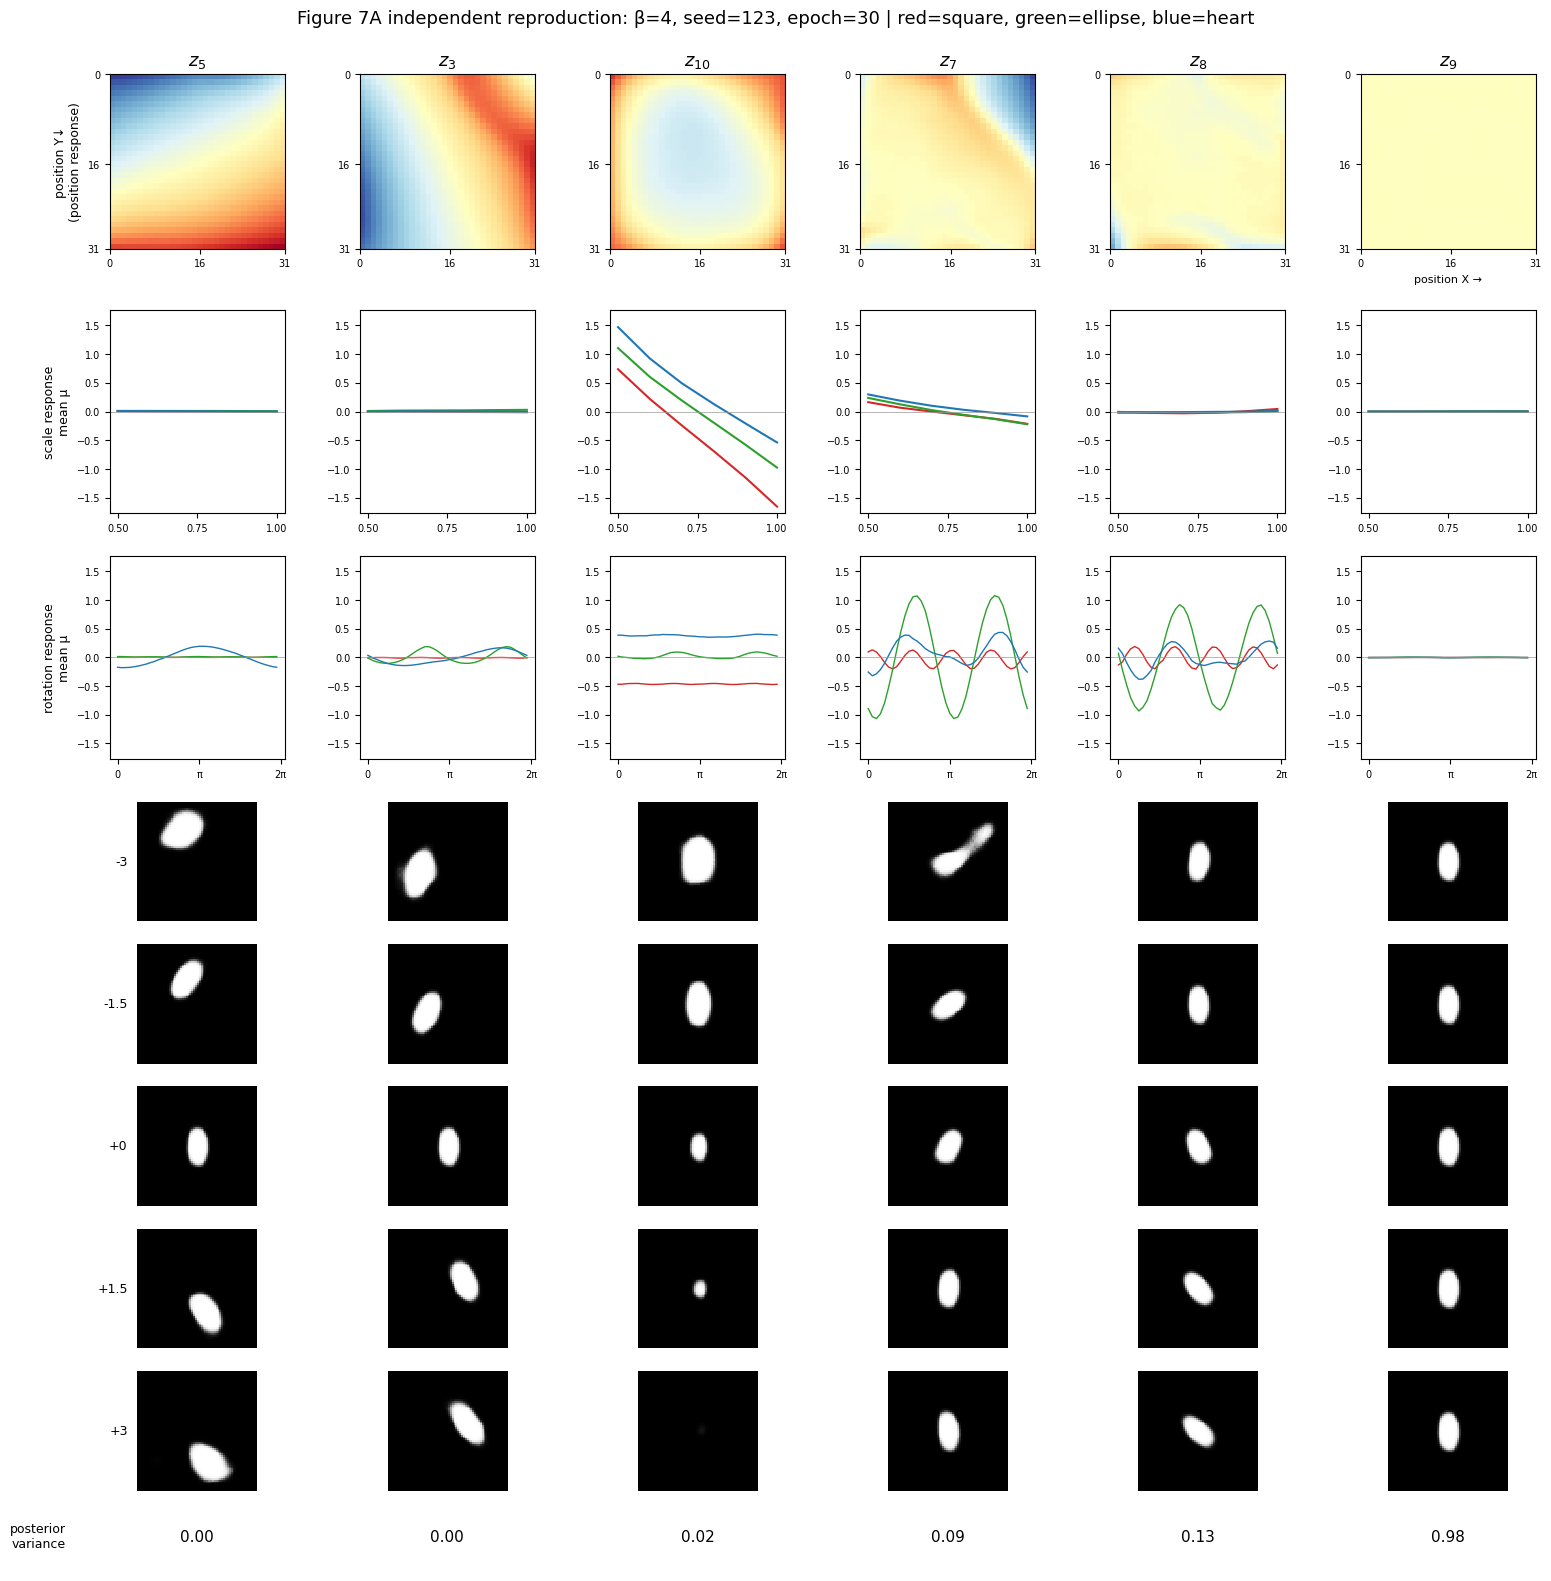

Saved figure: /content/drive/MyDrive/beta_vae_figure7_independent/beta4_seed123/figure7_paper_style_6_columns.png


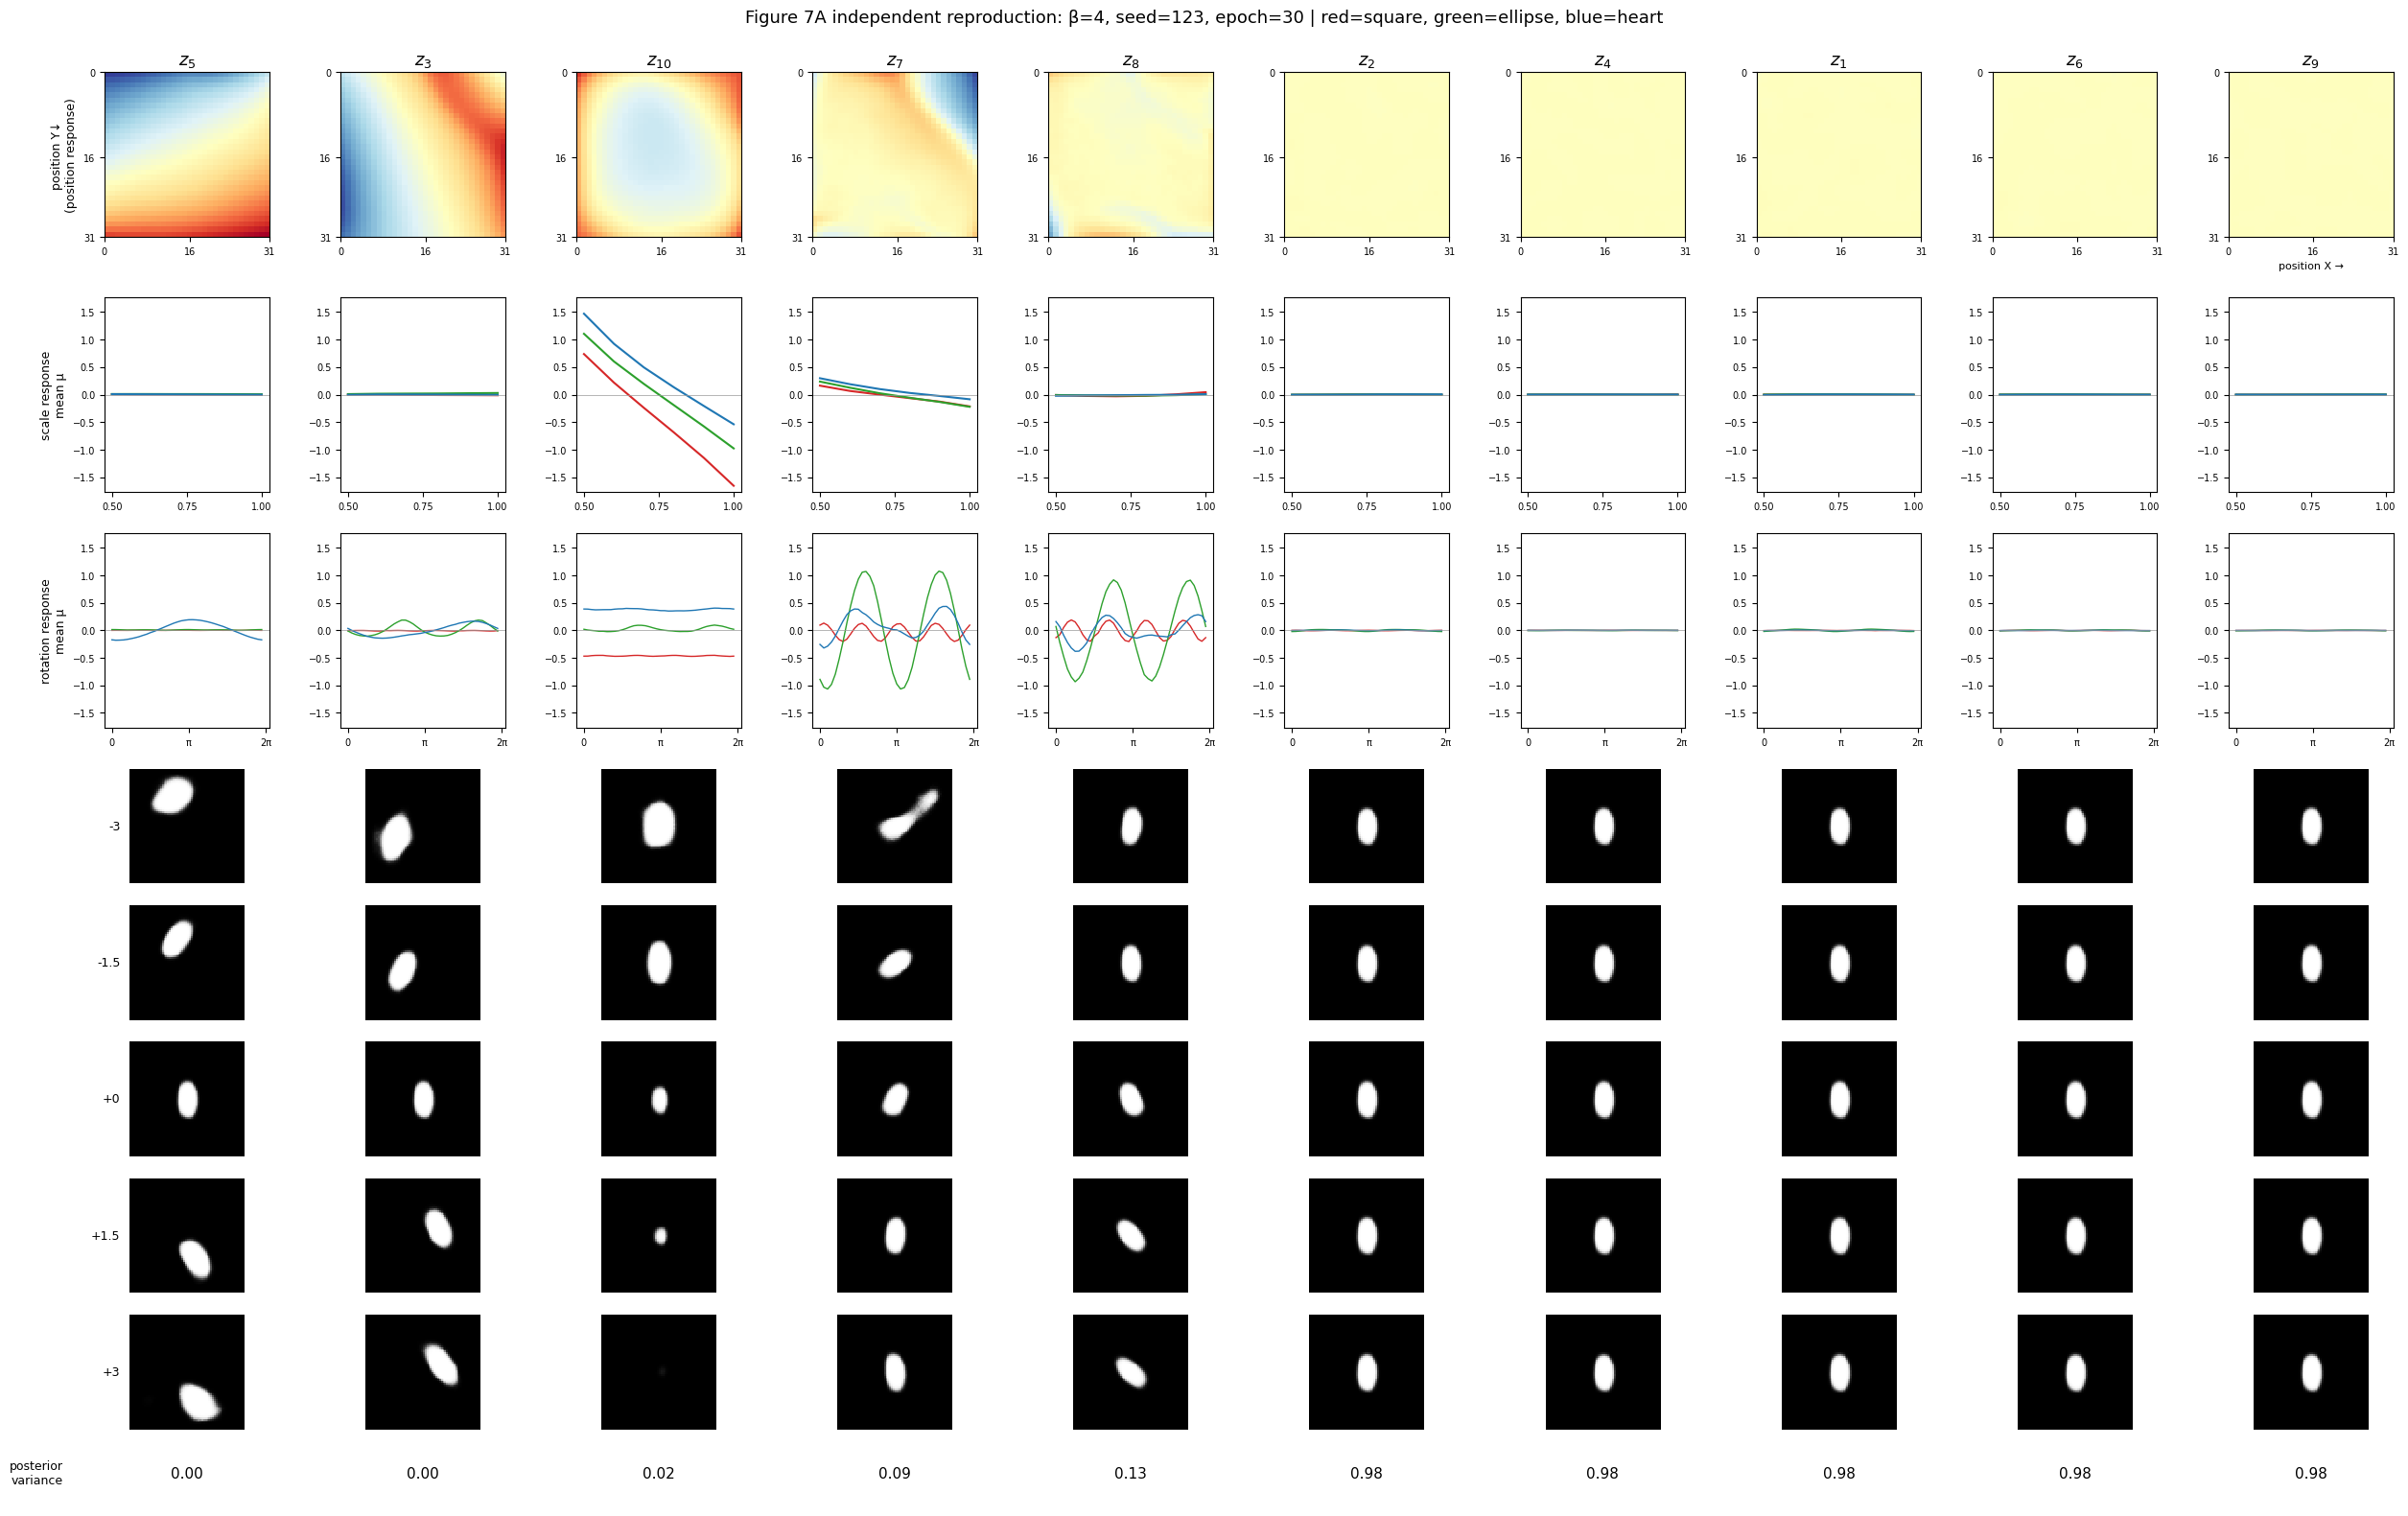

Saved figure: /content/drive/MyDrive/beta_vae_figure7_independent/beta4_seed123/figure7_all_10_latents.png


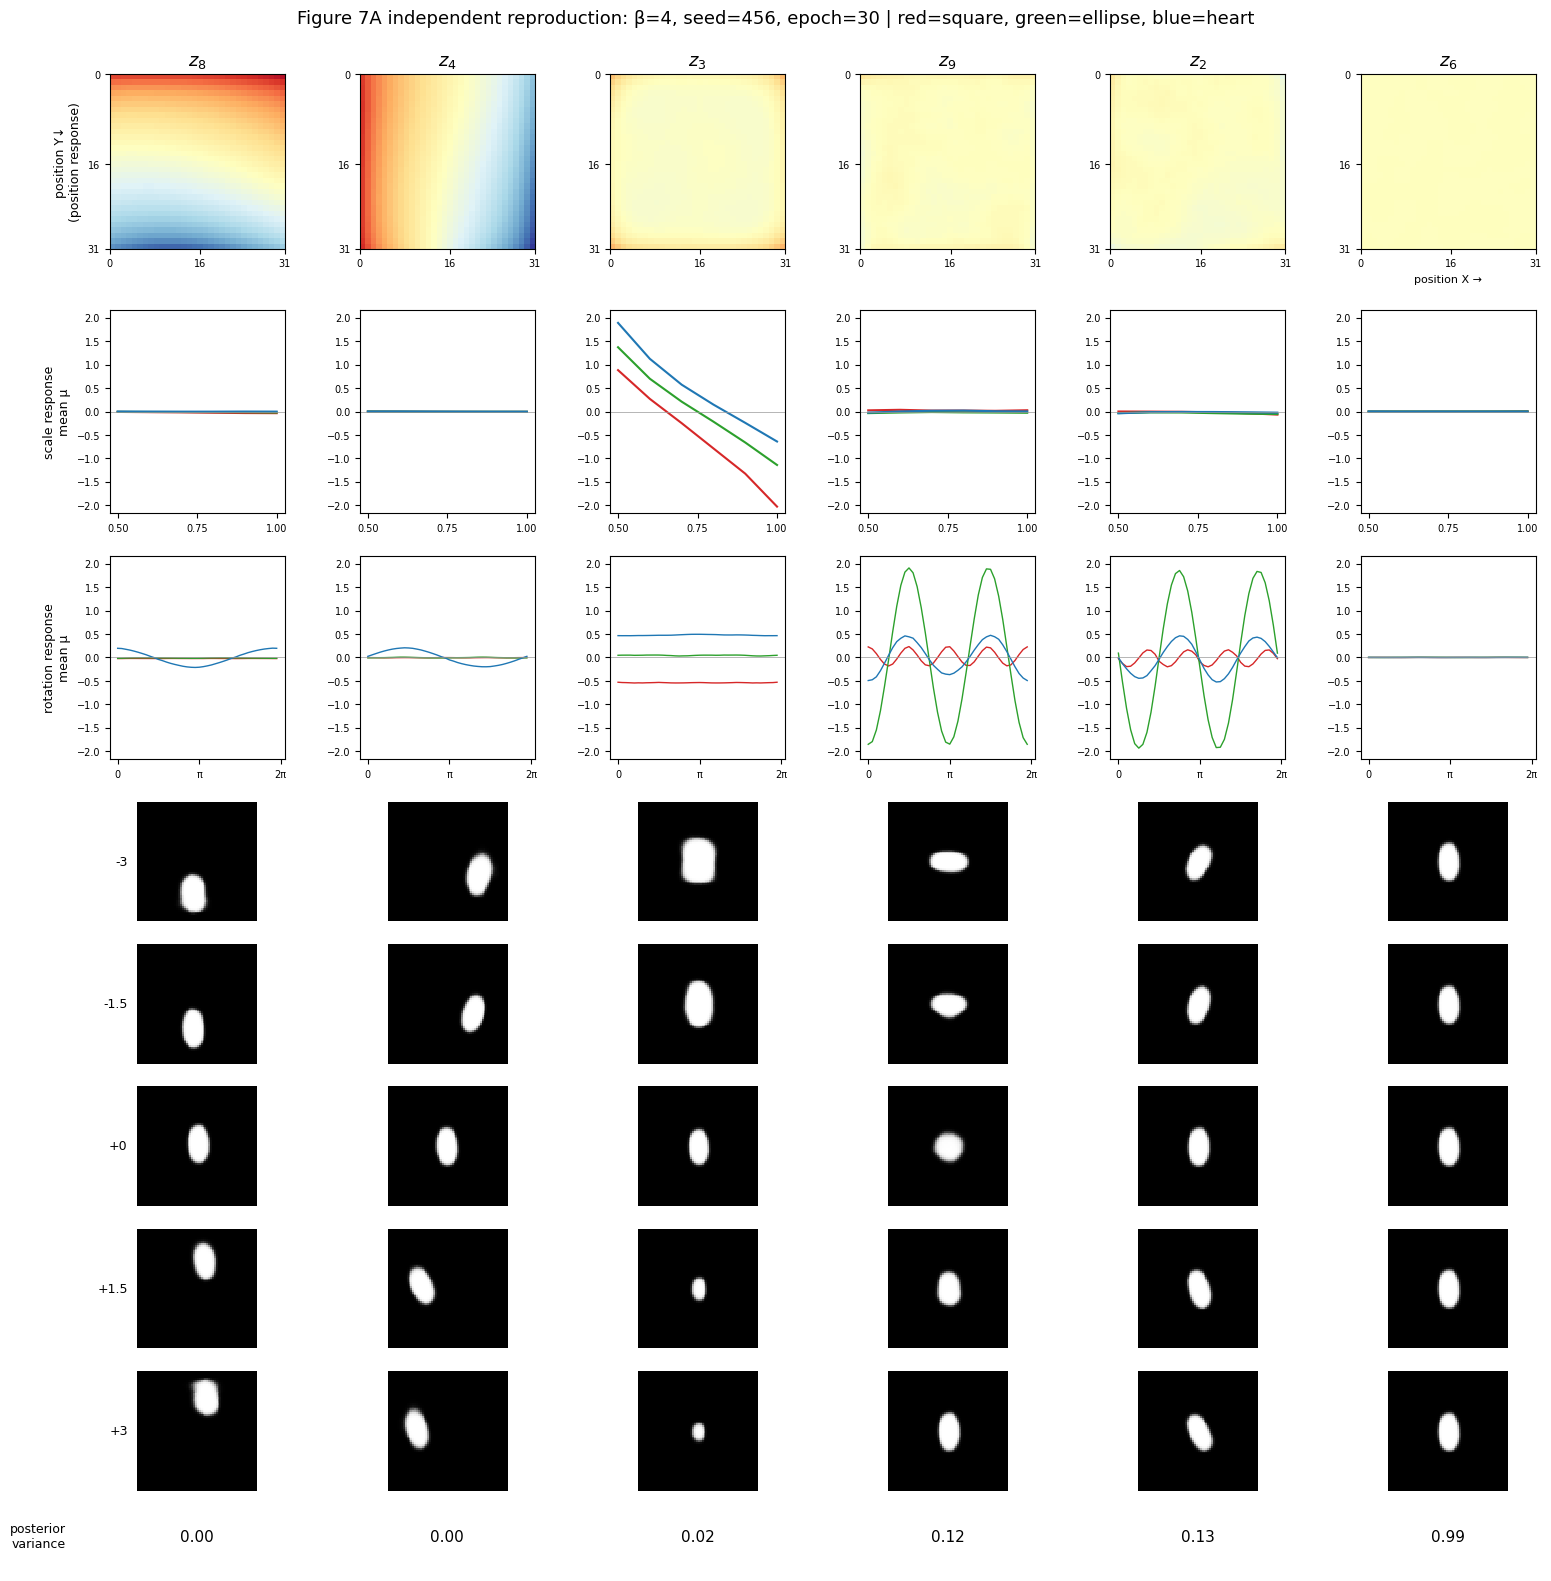

Saved figure: /content/drive/MyDrive/beta_vae_figure7_independent/beta4_seed456/figure7_paper_style_6_columns.png


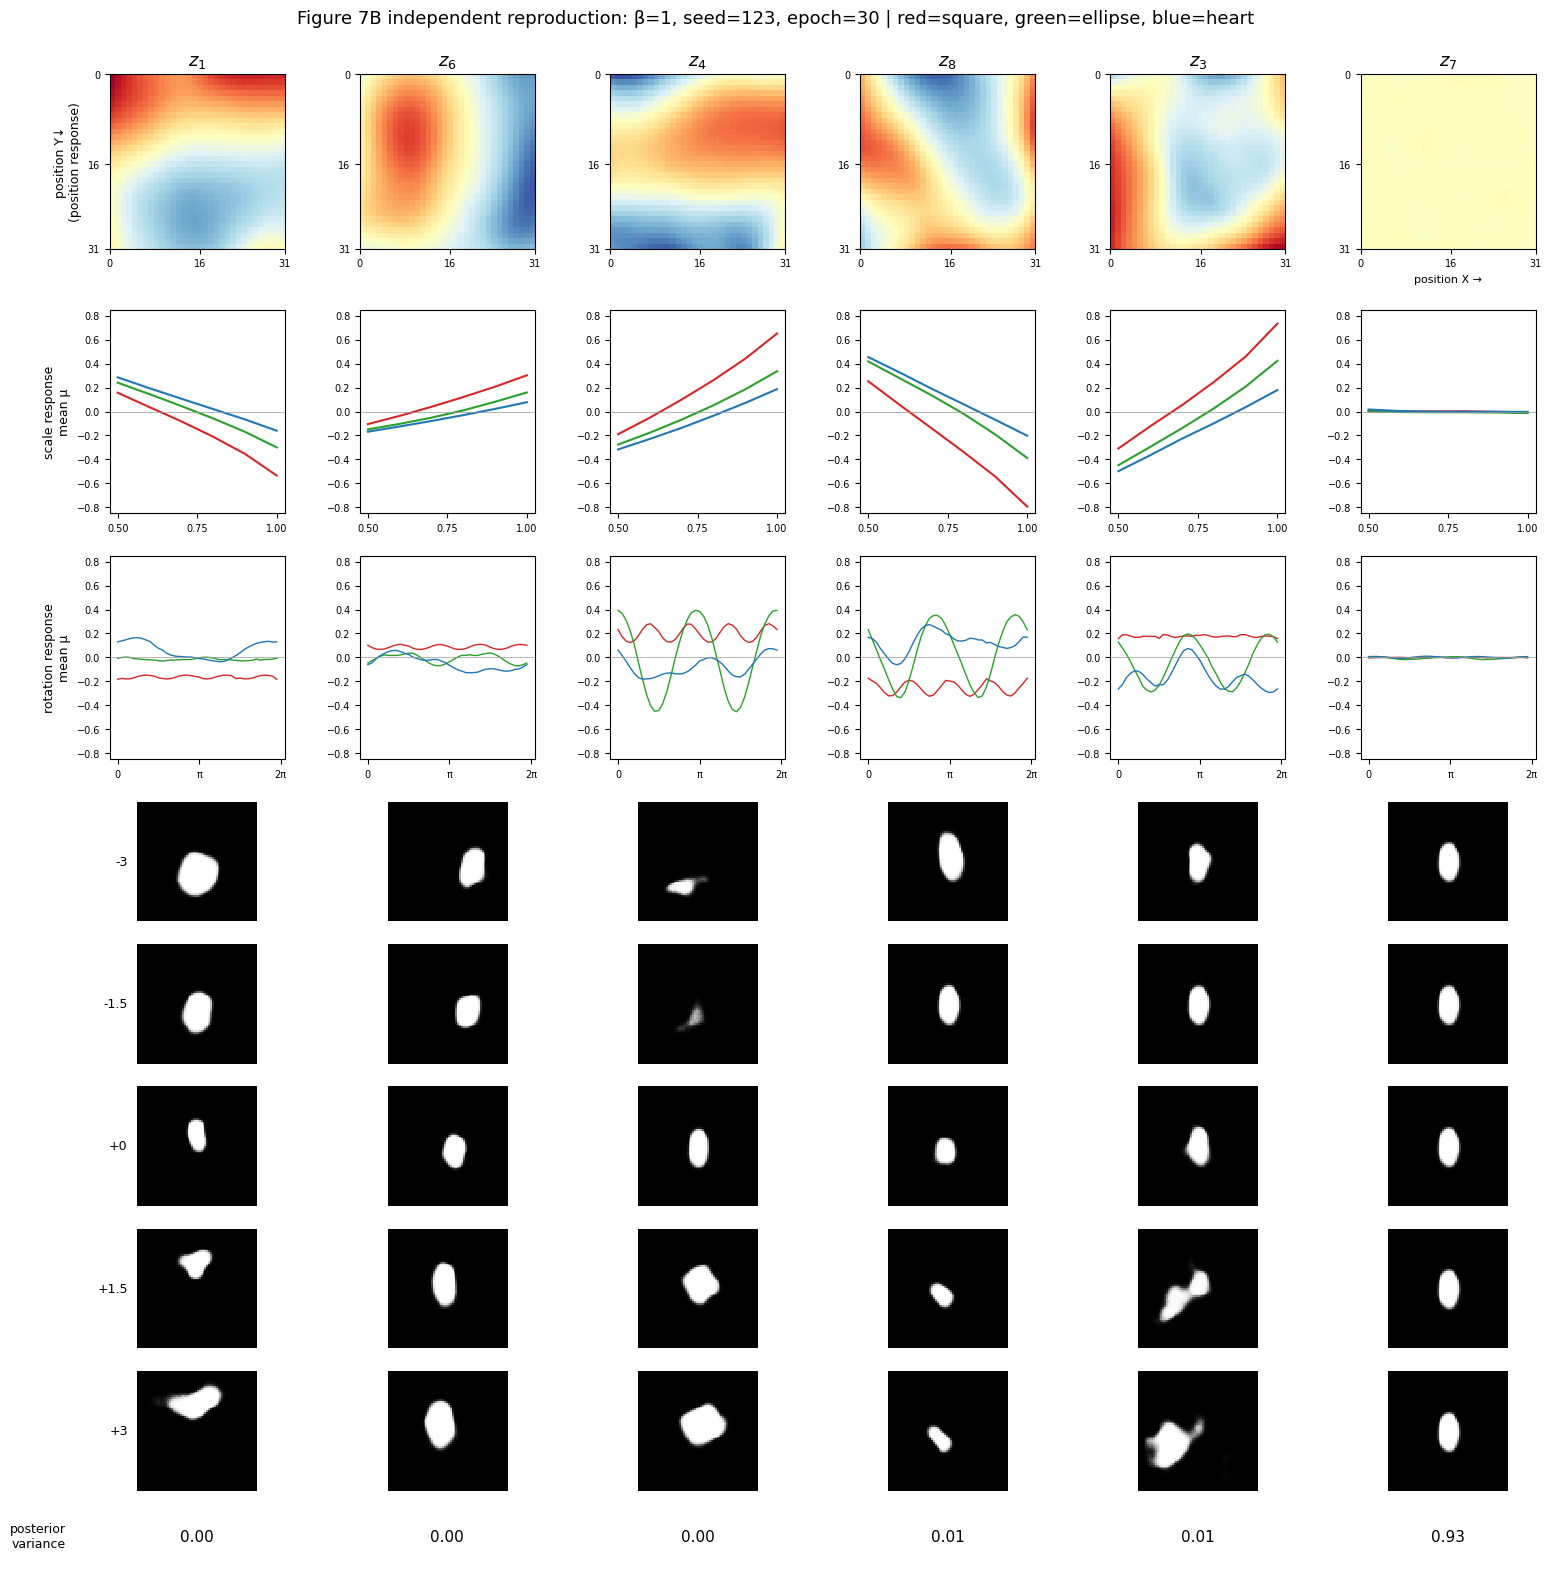

Saved figure: /content/drive/MyDrive/beta_vae_figure7_independent/beta1_seed123/figure7_paper_style_6_columns.png


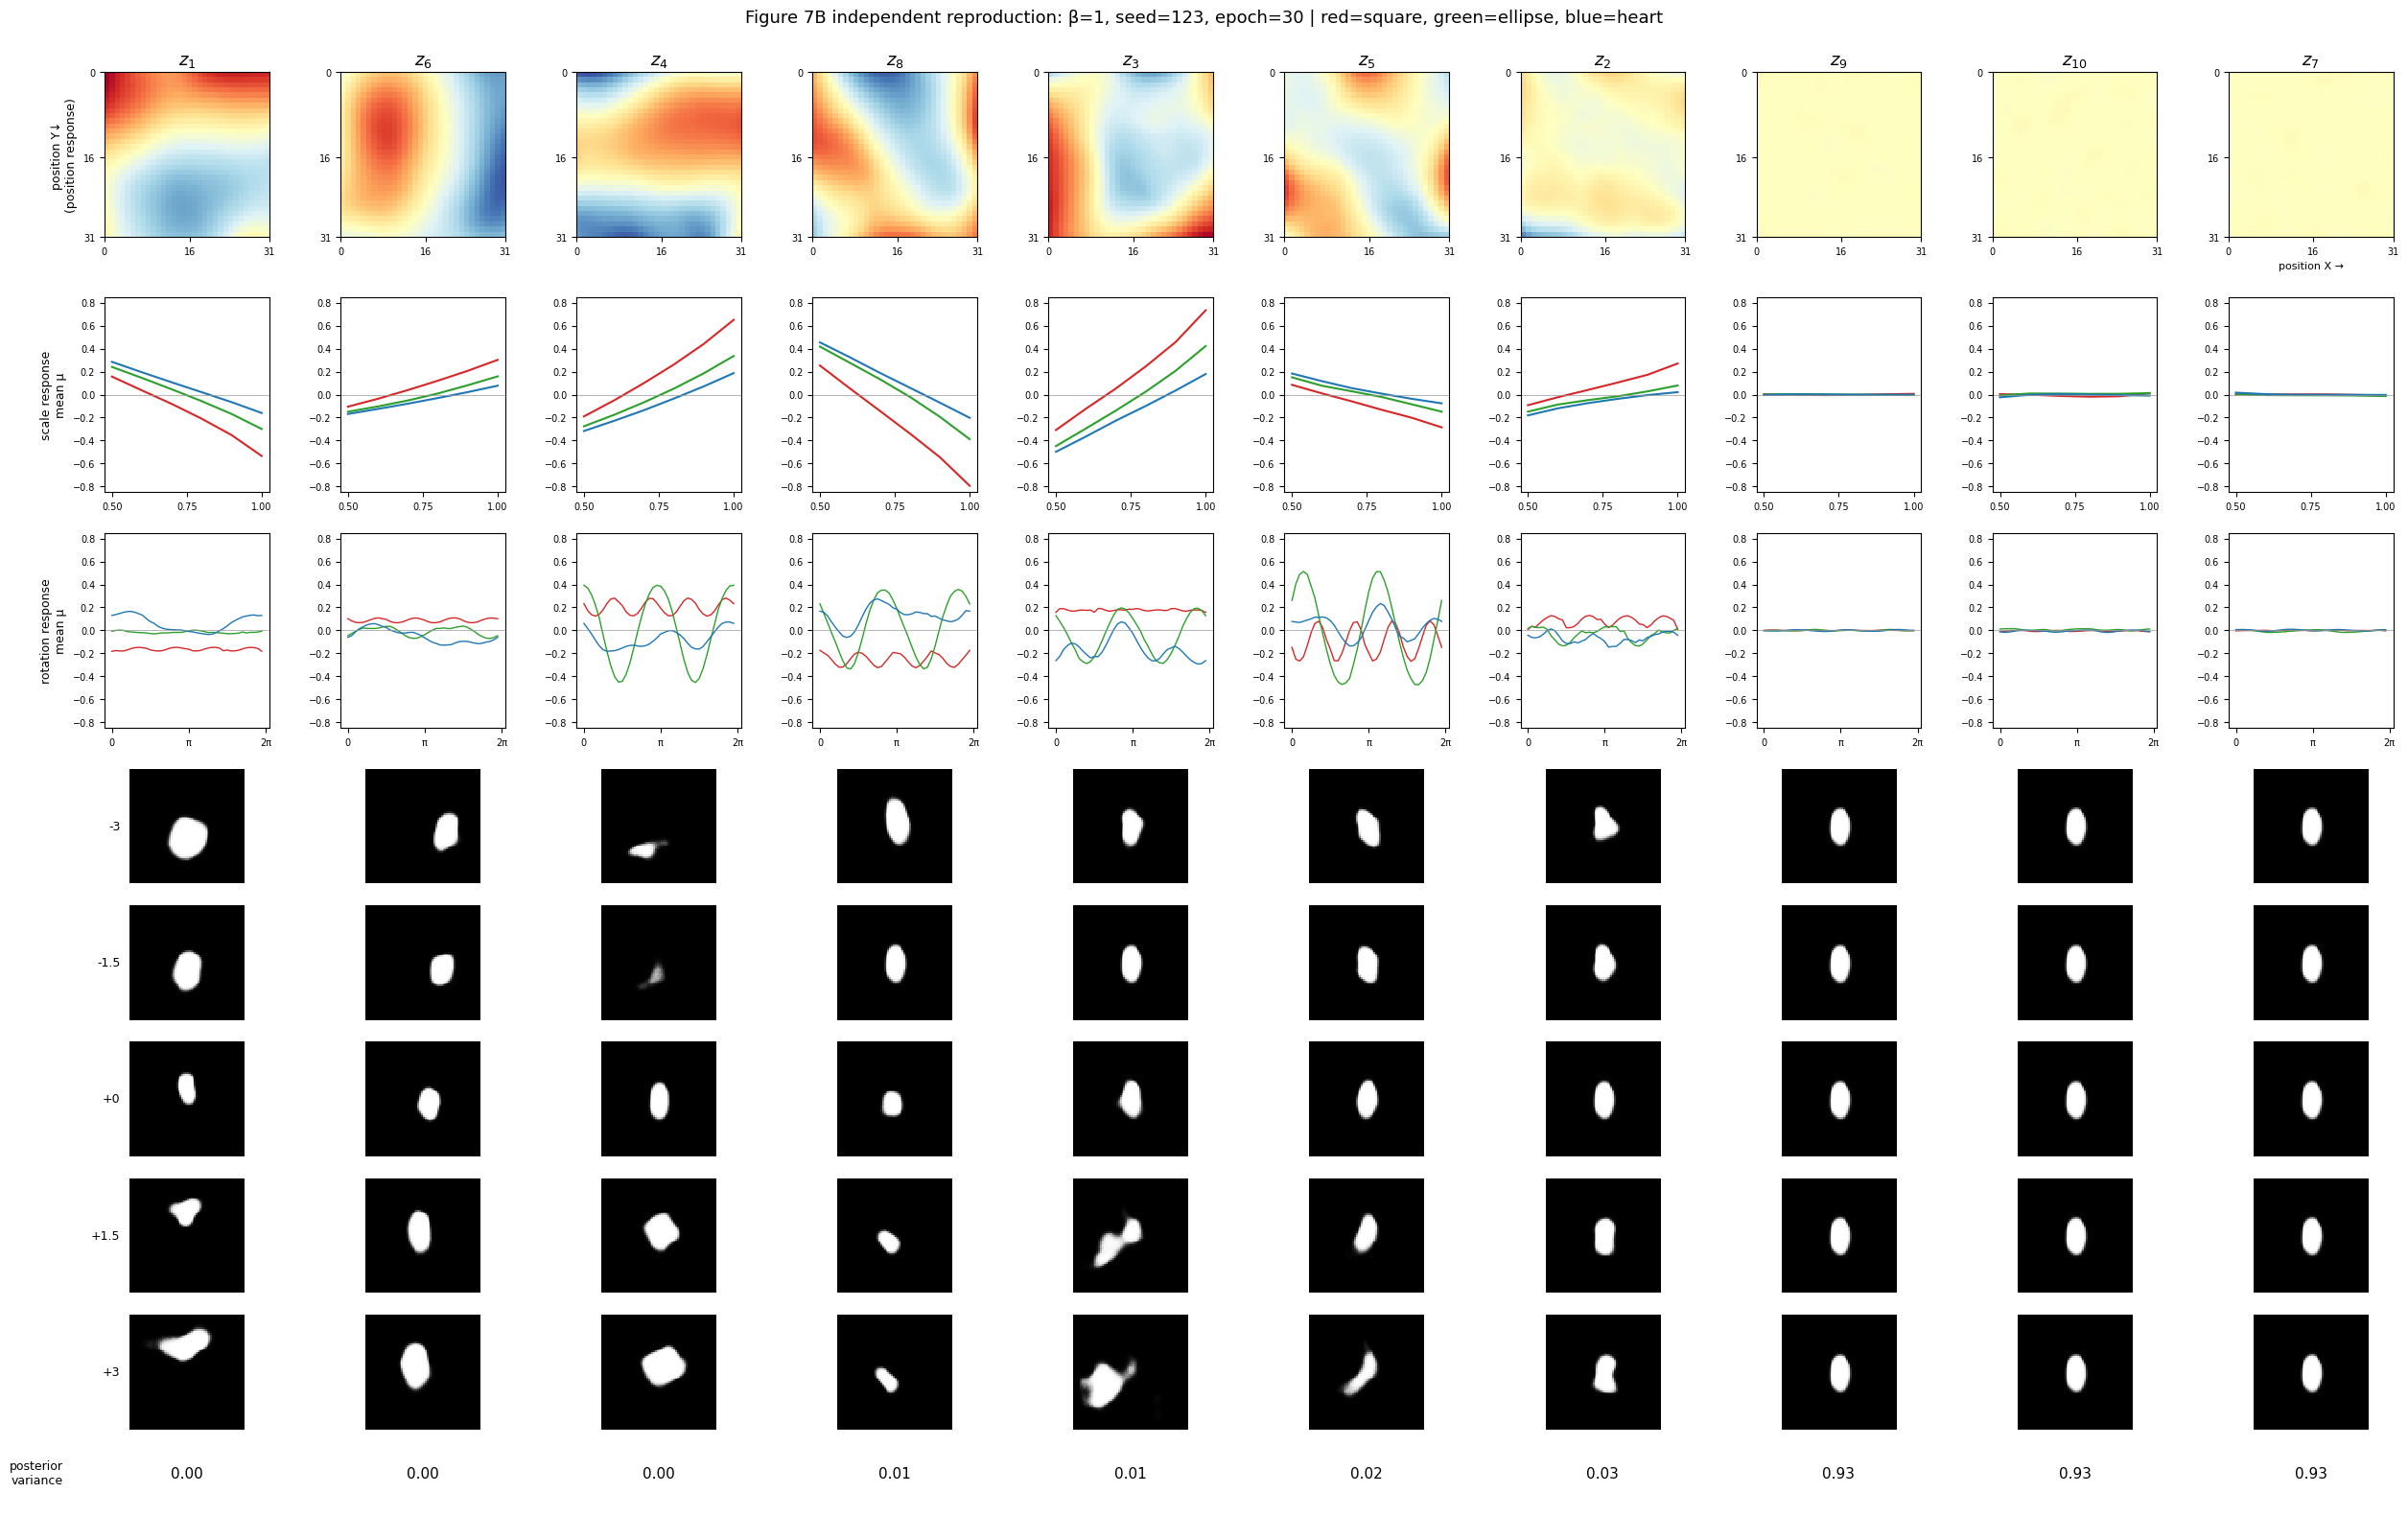

Saved figure: /content/drive/MyDrive/beta_vae_figure7_independent/beta1_seed123/figure7_all_10_latents.png


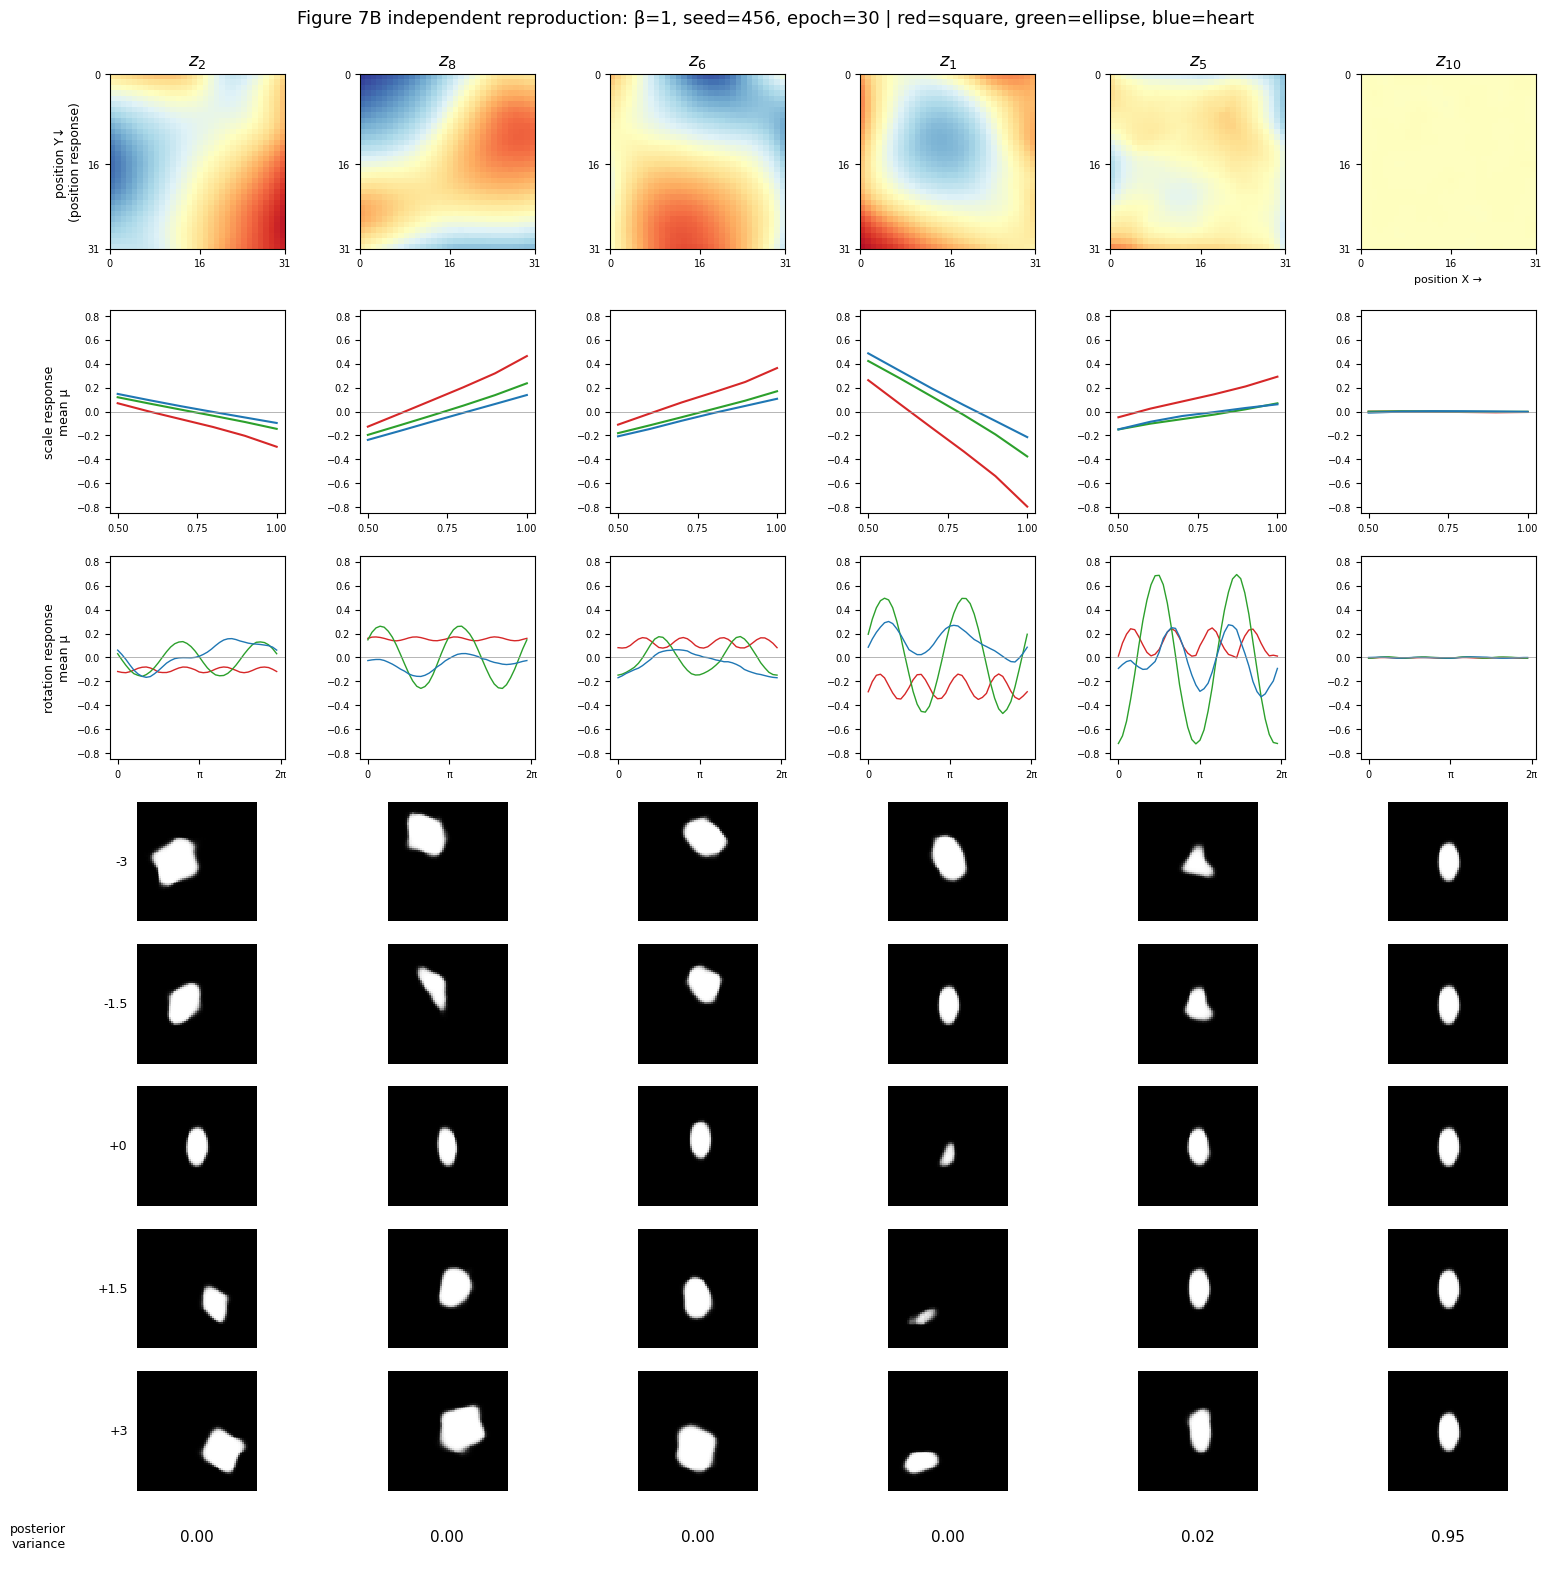

Saved figure: /content/drive/MyDrive/beta_vae_figure7_independent/beta1_seed456/figure7_paper_style_6_columns.png


In [ ]:
# Ensure stable anchor, single-image inference, and shape-specific plot colors.
ANCHOR_CLASSES=(0,1,3,10,16,16)  # ellipse, middle-ish scale, pi/2, centered.
ANCHOR_ID=int(np.ravel_multi_index(ANCHOR_CLASSES,FACTOR_SIZES))
assert torch.equal(CLASSES[ANCHOR_ID].cpu(),torch.tensor(ANCHOR_CLASSES))
TRAVERSAL_VALUES=np.linspace(-3.0,3.0,5,dtype=np.float32)
SHAPE_COLORS=['tab:red','tab:green','tab:blue']
SHAPE_NAMES=['square','ellipse','heart']
SCALE_VALS=np.linspace(0.5,1.0,6)
ROTATION_VALS=np.linspace(0.0,2*np.pi,40,endpoint=False)

@torch.inference_mode()
def decoded_traversals(model):
    model.eval()
    anchor=get_batch(torch.tensor([ANCHOR_ID],device=DEVICE))
    mu,logvar=model.encode(anchor)
    fixed=mu.float()[0]
    z=fixed[None,None,:].expand(Z_DIM,len(TRAVERSAL_VALUES),Z_DIM).clone()
    for j in range(Z_DIM):
        z[j,:,j]=torch.tensor(TRAVERSAL_VALUES,device=DEVICE)
    probabilities=torch.sigmoid(model.decode_logits(z.reshape(-1,Z_DIM)).float())
    return probabilities.reshape(Z_DIM,5,64,64).cpu().numpy(),\
           anchor.reshape(64,64).cpu().numpy(),fixed.cpu().numpy()


def plot_figure7(response,traversals,beta,seed,epoch,folder,paper_style=True):
    learned_var=response['mean_posterior_variance']
    ranked=np.argsort(learned_var)
    selected=list(ranked[:5])+[int(ranked[-1])] if paper_style else list(ranked)
    ncol=len(selected)
    figsize=((2.4*ncol)+1,15.7)
    fig=plt.figure(figsize=figsize,layout='constrained')
    gs=fig.add_gridspec(9,ncol,height_ratios=[2.1,1.7,1.7,1,1,1,1,1,.48],
                        hspace=0.13,wspace=0.14)
    # Shared zero-centered color scale: inactive dimensions shouldn't appear 'active' because noise is rescaled.
    pos=response['position']
    amp=max(float(np.max(np.abs(pos))),1e-4)
    all_curve=np.concatenate([response['shape_scale'].reshape(-1,Z_DIM),
                              response['shape_rotation'].reshape(-1,Z_DIM)],axis=0)
    curve_lim=max(float(np.max(np.abs(all_curve))),1e-3)*1.07
    for col,j in enumerate(selected):
        ax=fig.add_subplot(gs[0,col])
        ax.imshow(pos[:,:,j],origin='upper',extent=[0,31,31,0],cmap='RdYlBu_r',vmin=-amp,vmax=amp,aspect='equal')
        ax.set_title(f'$z_{{{j+1}}}$',fontsize=13)
        ax.set_xticks([0,16,31]); ax.set_yticks([0,16,31]);ax.tick_params(labelsize=7)
        if col==0:ax.set_ylabel('position Y↓\n(position response)',fontsize=9)
        if col==ncol-1:ax.set_xlabel('position X →',fontsize=8)
        ax=fig.add_subplot(gs[1,col])
        for s in range(3):ax.plot(SCALE_VALS,response['shape_scale'][s,:,j],color=SHAPE_COLORS[s],lw=1.5)
        ax.axhline(0,c='0.6',lw=.5);ax.set_ylim(-curve_lim,curve_lim)
        ax.set_xticks([.5,.75,1]);ax.tick_params(labelsize=7)
        if col==0:ax.set_ylabel('scale response\nmean μ',fontsize=9)
        ax=fig.add_subplot(gs[2,col])
        for s in range(3):ax.plot(ROTATION_VALS,response['shape_rotation'][s,:,j],color=SHAPE_COLORS[s],lw=1)
        ax.axhline(0,c='0.6',lw=.5);ax.set_ylim(-curve_lim,curve_lim)
        ax.set_xticks([0,np.pi,2*np.pi]);ax.set_xticklabels(['0','π','2π'],fontsize=7)
        ax.tick_params(axis='y',labelsize=7)
        if col==0:ax.set_ylabel('rotation response\nmean μ',fontsize=9)
        for t in range(5):
            ax=fig.add_subplot(gs[3+t,col])
            ax.imshow(traversals[j,t],cmap='gray',vmin=0,vmax=1,interpolation='nearest')
            ax.axis('off')
            if col==0:
                ax.text(-.08,.5,f'{TRAVERSAL_VALUES[t]:+g}',transform=ax.transAxes,
                        ha='right',va='center',fontsize=9)
        ax=fig.add_subplot(gs[8,col]);ax.axis('off')
        ax.text(.5,.6,f'{learned_var[j]:.2f}',ha='center',va='center',
                transform=ax.transAxes,fontsize=11)
        if col==0:ax.text(-.25,.6,'posterior\nvariance',ha='right',va='center',
                          transform=ax.transAxes,fontsize=9)
        # no true factor labels attached to coordinates: factor interpretation must come from the curves.
    suffix='paper_style_6_columns' if paper_style else 'all_10_latents'
    fig.suptitle(f'Figure 7{"A" if beta==4 else "B"} independent reproduction: '
                 f'β={beta:g}, seed={seed}, epoch={epoch} | '
                 'red=square, green=ellipse, blue=heart',fontsize=13)
    path=folder/f'figure7_{suffix}.png'
    fig.savefig(path,dpi=180,bbox_inches='tight')
    plt.show();plt.close(fig)
    print('Saved figure:',path)
    return path

# Every seed gets a paper-like plot; the pre-registered first seed also gets the all-10 variant.
for beta in BETAS:
    for seed in SEEDS:
        folder=run_dir(beta,seed)
        model,ckpt=load_trained(beta,seed,return_checkpoint=True)
        tr,anchor,base_z=decoded_traversals(model)
        response=RESPONSES[(beta,seed)]
        plot_figure7(response,tr,beta,seed,ckpt['epoch'],folder,paper_style=True)
        if seed==SEEDS[0]:
            plot_figure7(response,tr,beta,seed,ckpt['epoch'],folder,paper_style=False)
        np.savez_compressed(folder/'traversal_data.npz',traversals=tr,anchor=anchor,
                            inferred_anchor_mean=base_z,values=TRAVERSAL_VALUES,
                            epoch=ckpt['epoch'])
        del model,ckpt,tr;gc.collect();torch.cuda.empty_cache()

## 7. Reconstruction fidelity, factor selectivity, and β comparison

A good reproduction **does not require the exact same latent index** as the paper. Instead inspect:

1. Which position response maps change nearly exclusively along X or Y?
2. Does scale have one dominant coordinate, or multiple entangled ones?
3. Is rotation shape-dependent (particularly square's orientation symmetry)?
4. Are learned posterior variances close to 1 and KL contributions close to 0 for unused dimensions?
5. Do individual traversals yield one interpretable change, or jointly change scale/location/orientation?
6. Does β=1 achieve lower reconstruction loss but more mixed features? There is no universal guarantee.

The optional factor `R²` is computed post hoc using labels and only measures main effects. A seed that looks visually successful does not establish stability. Do not select the most flattering seed after seeing outcomes.

β=4, seed=123: BCE=60.45, IoU=0.861, pixel acc=0.994, active KL dims=5/10
  Ordered z indices (1-indexed): [5, 3, 10, 7, 8, 2, 4, 1, 6, 9]
  Ordered variances: [0.002, 0.005, 0.016, 0.088, 0.133, 0.98, 0.98, 0.983, 0.984, 0.985]
β=4, seed=456: BCE=55.66, IoU=0.873, pixel acc=0.995, active KL dims=5/10
  Ordered z indices (1-indexed): [8, 4, 3, 9, 2, 5, 7, 10, 1, 6]
  Ordered variances: [0.002, 0.002, 0.021, 0.118, 0.128, 0.979, 0.98, 0.981, 0.982, 0.986]
β=1, seed=123: BCE=40.76, IoU=0.912, pixel acc=0.996, active KL dims=7/10
  Ordered z indices (1-indexed): [1, 6, 4, 8, 3, 5, 2, 9, 10, 7]
  Ordered variances: [0.001, 0.001, 0.002, 0.005, 0.008, 0.015, 0.031, 0.927, 0.927, 0.934]
β=1, seed=456: BCE=45.04, IoU=0.901, pixel acc=0.996, active KL dims=6/10
  Ordered z indices (1-indexed): [2, 8, 6, 1, 5, 9, 3, 7, 4, 10]
  Ordered variances: [0.001, 0.001, 0.001, 0.004, 0.016, 0.018, 0.937, 0.937, 0.942, 0.949]


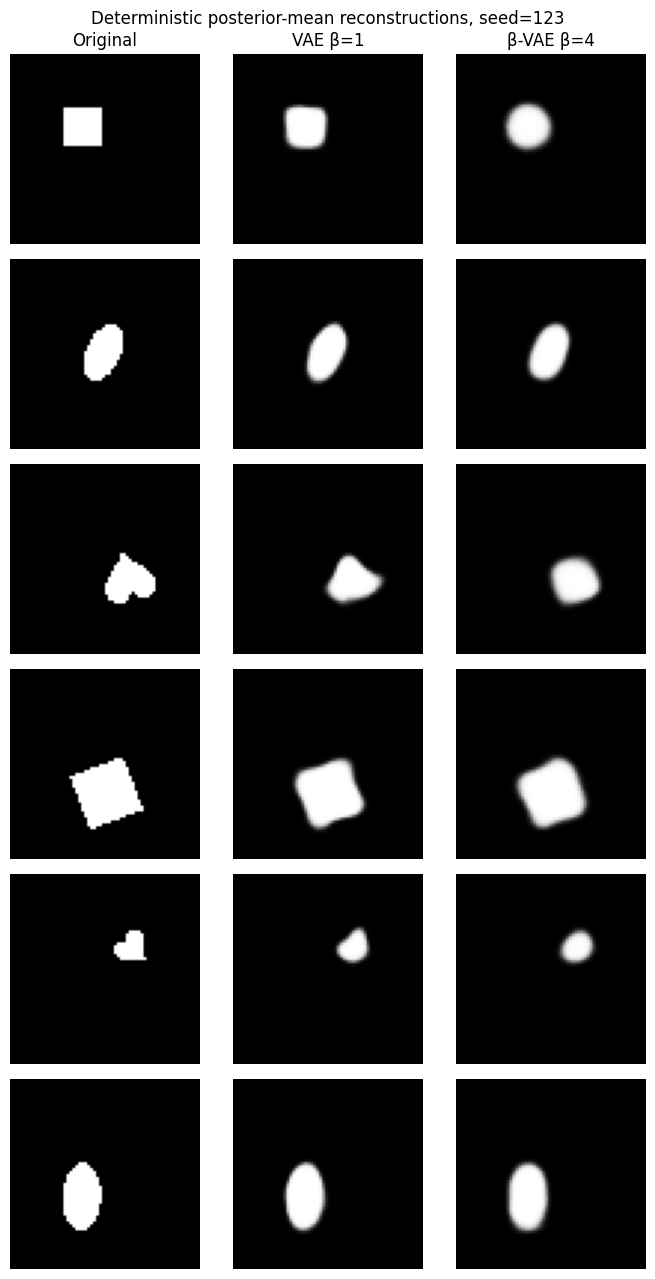

In [ ]:
# Same pre-registered images for reconstruction comparison across models.
PRIMARY_SEED=SEEDS[0]
RECON_IDS=[int(np.ravel_multi_index((0,s,sc,ori,x,y),FACTOR_SIZES))
           for s,sc,ori,x,y in [
              (0,2,0,8,8),(1,3,7,15,15),(2,4,21,23,21),
              (0,5,12,16,25),(2,1,5,25,9),(1,4,29,8,23)]]

@torch.inference_mode()
def reconstruction_metrics(model,indices):
    x=get_batch(torch.as_tensor(indices,device=DEVICE))
    mu,_=model.encode(x)
    logits=model.decode_logits(mu.float())
    prob=torch.sigmoid(logits.float())
    bce=F.binary_cross_entropy_with_logits(logits.float(),x,reduction='none').sum(-1).mean().item()
    gt=x>0.5; pred=prob>0.5
    iou=((gt&pred).sum(-1).float()/(gt|pred).sum(-1).clamp_min(1)).mean().item()
    acc=(gt==pred).float().mean().item()
    return bce,iou,acc,prob.reshape(-1,64,64).cpu().numpy()

# Report with a larger fixed train-subset (not a held-out test set).
metric_ids=np.linspace(0,N-1,num=4096,dtype=np.int64)
metrics={}
first_model_images={}
for beta in BETAS:
    for seed in SEEDS:
        model,ckpt=load_trained(beta,seed,return_checkpoint=True)
        mbce=miou=macc=0.0
        for i in range(0,len(metric_ids),512):
            bce,iou,acc,_=reconstruction_metrics(model,metric_ids[i:i+512])
            weight=len(metric_ids[i:i+512])/len(metric_ids)
            mbce+=bce*weight;miou+=iou*weight;macc+=acc*weight
        resp=RESPONSES[(beta,seed)]
        ranked=np.argsort(resp['mean_posterior_variance'])
        active=(resp['mean_kl_per_dim'] > .05) # HEURISTIC not a categorical ground truth
        metrics[f'beta{int(beta)}_seed{seed}']={
            'epoch':int(ckpt['epoch']),'deterministic_mu_reconstruction_BCE_per_image':mbce,
            'foreground_IoU_at_0p5':miou,'pixel_accuracy_at_0p5':macc,
            'active_kl_gt_0p05':int(active.sum()),
            'latent_order_1_indexed':(ranked+1).tolist(),
            'mean_posterior_variance':resp['mean_posterior_variance'].tolist(),
            'per_latent_kl_nats':resp['mean_kl_per_dim'].tolist(),
        }
        print(f'β={beta:g}, seed={seed}: BCE={mbce:.2f}, IoU={miou:.3f}, '
              f'pixel acc={macc:.3f}, active KL dims={sum(active)}/10')
        print('  Ordered z indices (1-indexed):', (ranked+1).tolist())
        print('  Ordered variances:',np.round(resp['mean_posterior_variance'][ranked],3).tolist())
        if seed==PRIMARY_SEED:
            _,_,_,imgs=reconstruction_metrics(model,RECON_IDS)
            first_model_images[beta]=imgs
        del model,ckpt
(ROOT/'reconstruction_metrics.json').write_text(json.dumps(metrics,indent=2))

x_ref=get_batch(torch.tensor(RECON_IDS,device=DEVICE)).cpu().numpy().reshape(-1,64,64)
fig,axes=plt.subplots(len(RECON_IDS),3,figsize=(7,13))
for i in range(len(RECON_IDS)):
    for j,img in enumerate([x_ref[i],first_model_images[1.0][i],first_model_images[4.0][i]]):
        axes[i,j].imshow(img,cmap='gray',vmin=0,vmax=1)
        axes[i,j].axis('off')
        if i==0:axes[i,j].set_title(['Original','VAE β=1','β-VAE β=4'][j])
fig.suptitle(f'Deterministic posterior-mean reconstructions, seed={PRIMARY_SEED}')
fig.tight_layout()
fig.savefig(ROOT/'reconstruction_comparison.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)

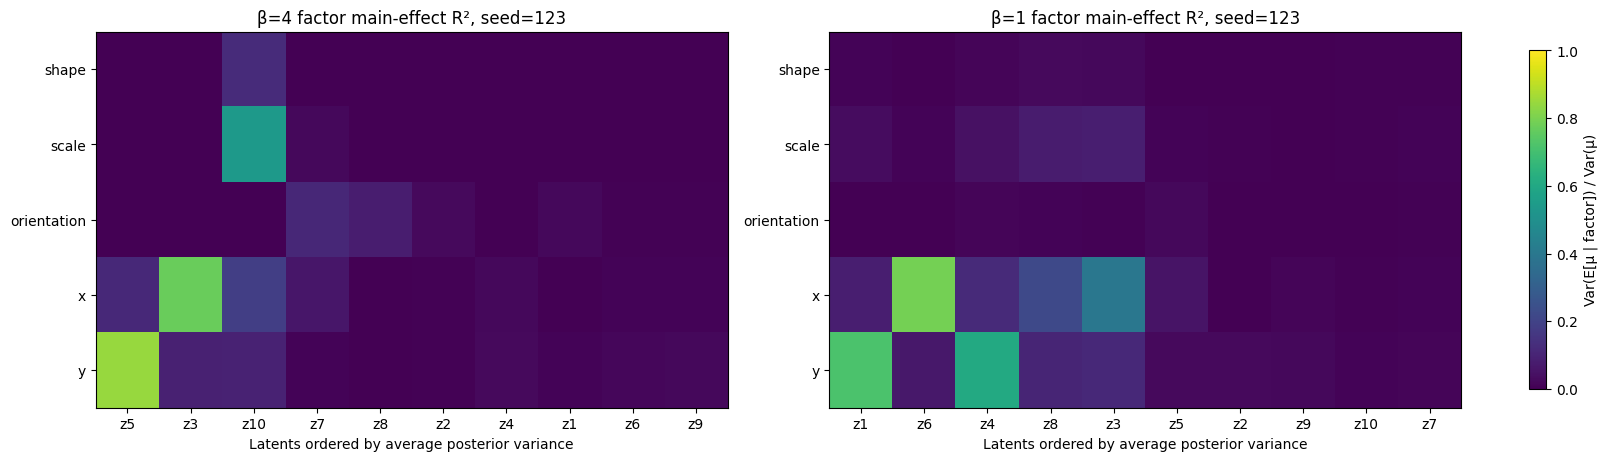

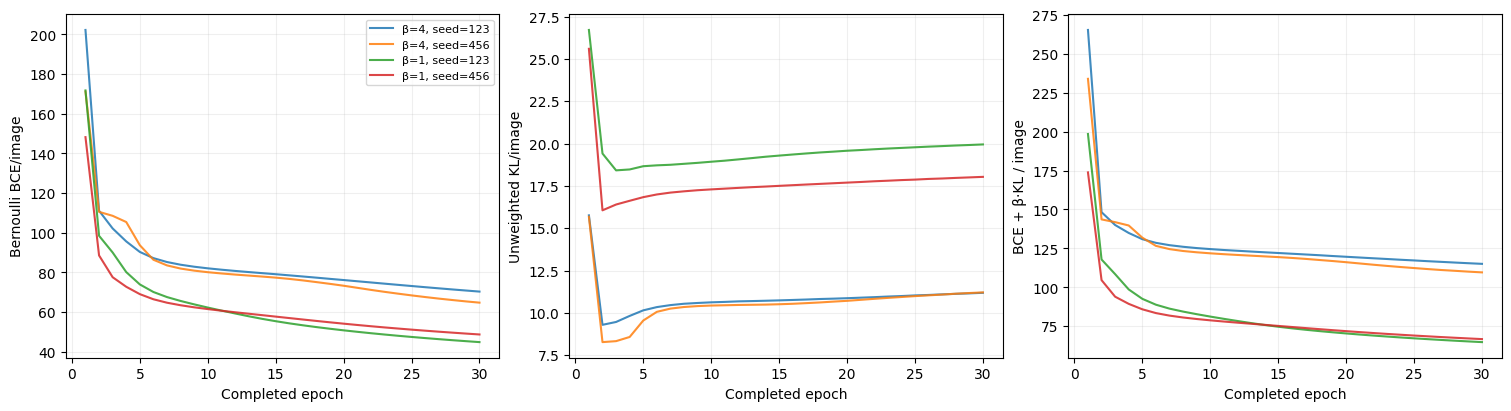

In [ ]:
# Post-hoc main-effect factor scores: which dimension responds to which label?
fig,axs=plt.subplots(1,2,figsize=(16,4.5),layout='constrained')
for i,beta in enumerate([4.0,1.0]):
    resp=RESPONSES[(beta,PRIMARY_SEED)]
    order=np.argsort(resp['mean_posterior_variance'])
    scores=resp['factor_r2'][:,order]
    im=axs[i].imshow(scores,aspect='auto',cmap='viridis',vmin=0,vmax=1)
    axs[i].set_xticks(np.arange(10),[f'z{j+1}' for j in order]);axs[i].set_yticks(range(5),FACTOR_NAMES)
    axs[i].set_title(f'β={beta:g} factor main-effect R², seed={PRIMARY_SEED}')
    axs[i].set_xlabel('Latents ordered by average posterior variance')
fig.colorbar(im,ax=axs,label='Var(E[μ | factor]) / Var(μ)',shrink=.9)
fig.savefig(ROOT/'factor_r2_diagnostics.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)

# Training curves; plot reported quantities separately rather than conflate loss scaling.
fig,axes=plt.subplots(1,3,figsize=(15,4),layout='constrained')
keys=['train_bce_per_image','train_kl_per_image','train_total_per_image']
labels=['Bernoulli BCE/image','Unweighted KL/image','BCE + β·KL / image']
for beta in BETAS:
    for seed in SEEDS:
        history=json.loads((run_dir(beta,seed)/'history.json').read_text())
        for ax,key in zip(axes,keys):
            ax.plot([v['epoch'] for v in history],[v[key] for v in history],
                    label=f'β={beta:g}, seed={seed}',alpha=.85)
for ax,label in zip(axes,labels):
    ax.set(xlabel='Completed epoch',ylabel=label)
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.savefig(ROOT/'training_curves.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)

## 8. Interpretation and failure tracking checklist (fill in after actual runs)

**Expected, but not guaranteed:** β=4 may make a small group of low-variance/large-KL dimensions respond predominantly to X, Y, scale and orientation, while β=1 may encode more coupled factors. Unused dimensions should tend toward posterior variance 1, inferred mean 0, KL≈0. A higher β limits information capacity more strongly and may lower reconstruction quality; increasing β indefinitely is **not** a guarantee of greater disentanglement. β<1 relaxes the constraint, generally favoring reconstruction, but may entangle factors.

**Keep the distinction:** The paper's latent numbering and reference images are seed dependent. Semantic alignment needs only an appropriate permutation, not exact z-index matching. For the paper's claim, compare *qualitative selectivity* in heatmaps, shape-colored curves, traversals, and multiple seeds; full-data posterior variance/KL and IoU/BCE add objective checks.

**Known deviations to disclose:** Unspecified batch 256/30 epochs; fixed chosen reference image; original visualization's exact color normalization unknown; 10-column supplementary plot; numeric stabilization `BCEWithLogits`; optional acceleration flags if enabled. The paper did not provide enough details to guarantee bitwise reproduction. The notebook does not claim the originals' latent names, exact intensities, or exact image anchor.

**If experiment fails:** edit `FAILURE_LOG.md` with the actual symptom, checkpoint/seed, evidence from BCE/KL trajectories, diagnostic intervention, and observed before/after change. Typical tests to perform *if warranted by evidence* include inspecting pixel summation vs mean, checking separate decoder nonlinearities, confirming data factor labels, observing posterior collapse (KL≈0 for all coordinates), extending epochs from checkpoint, or comparing float32/BF16 without changing β. **Do not silently retune optimizer or cherry-pick seeds.**

**Assignment Phase 3 boundary:** commit/share this independent notebook and records **before** any reference-code comparison in Phase 4. For your report, include the original and generated Figure 7, list the LLM name (`GPT-6`) and its share link, give the public GitHub link only on the instructed submission date, and report all actual failures and corrections. No Phase-4 code should be consulted at this stage.

In [ ]:
# Final reproducibility manifest: machine-readable summary without inventing success.
manifest={'experiment':'Independent Higgins (2017) Fig 7A/B',
          'config':DECISIONS,'environment':ENV,'model_results':metrics,
          'paths':{'root':str(ROOT),'failure_log':str(FAILURES_PATH)},
          'dataset_archive':DS_NAME,
          'notes': 'Rows are computed from trained checkpoint posteriors on the entire original dSprites dataset.'}
(ROOT/'RUN_MANIFEST.json').write_text(json.dumps(manifest,indent=2))
print('Saved manifest:',ROOT/'RUN_MANIFEST.json')
print('Saved failure log:',FAILURES_PATH)
print('Complete. Examine *actual* figures and numerical results before claiming reproduction.')

Saved manifest: /content/drive/MyDrive/beta_vae_figure7_independent/RUN_MANIFEST.json
Saved failure log: /content/drive/MyDrive/beta_vae_figure7_independent/FAILURE_LOG.md
Complete. Examine *actual* figures and numerical results before claiming reproduction.
